# EDA (домен offers)

## 0. Загрузка данных

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.decomposition import PCA

PATH = Path("t_ecd_data/dataset/small/")

In [2]:
events = pl.scan_parquet(PATH / "offers/events/*.pq")
items = pl.read_parquet(PATH / "offers/items.pq")
brands = pl.read_parquet(PATH / "brands.pq")
users = pl.read_parquet(PATH / "users.pq")

for name, df in [("events", events), ("items", items), ("brands", brands), ("users", users)]:
    schema = df.collect_schema() if isinstance(df, pl.LazyFrame) else df.schema
    print(f"{name}: {dict(schema)}\n")

events: {'timestamp': Duration(time_unit='us'), 'user_id': UInt64, 'item_id': String, 'action_type': String}

items: {'item_id': String, 'brand_id': UInt64, 'embedding': Array(Float32, shape=(312,))}

brands: {'brand_id': UInt64, 'embedding': Array(Float32, shape=(300,))}

users: {'user_id': UInt64, 'socdem_cluster': UInt8, 'region': UInt8}



## 1. Качество данных

### 1.1. Схемы и базовые статистики

In [3]:
def describe_small(name, df):
    n = df.height
    print(f"\n===== {name}: {n:,} строк")
    print(df.select(pl.exclude("embedding")).describe())
    for col in df.columns:
        nulls = df[col].null_count()
        line = f"{col:<15} пропусков: {nulls:>7,} из {n:,} ({nulls / n:.2%})"
        if col != "embedding":
            un = df[col].drop_nulls().n_unique()
            line += f" | уникальных: {un:,}"
        print(line)

describe_small("items", items)
describe_small("brands", brands)
describe_small("users", users)


===== items: 22,368 строк
shape: (9, 3)
┌────────────┬────────────┬───────────────┐
│ statistic  ┆ item_id    ┆ brand_id      │
│ ---        ┆ ---        ┆ ---           │
│ str        ┆ str        ┆ f64           │
╞════════════╪════════════╪═══════════════╡
│ count      ┆ 22368      ┆ 21826.0       │
│ null_count ┆ 0          ┆ 542.0         │
│ mean       ┆ null       ┆ 125055.585723 │
│ std        ┆ null       ┆ 73032.772814  │
│ min        ┆ offer_1000 ┆ 87.0          │
│ 25%        ┆ null       ┆ 64692.0       │
│ 50%        ┆ null       ┆ 121805.0      │
│ 75%        ┆ null       ┆ 187727.0      │
│ max        ┆ offer_9997 ┆ 251377.0      │
└────────────┴────────────┴───────────────┘
item_id         пропусков:       0 из 22,368 (0.00%) | уникальных: 22,368
brand_id        пропусков:     542 из 22,368 (2.42%) | уникальных: 5,683
embedding       пропусков:       0 из 22,368 (0.00%)

===== brands: 29,485 строк
shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ brand_id   

**Выводы**
- `describe` для `user_id`, `brand_id`, `region` и `socdem_cluster` смысла не имеет: это идентификаторы и закодированные категории. Для них смотрим число уникальных значений и пропуски
- `item_id` и `user_id` уникальны, значит полных дублей строк в items и users нет
- `brand_id` в brands не уникален: 29 453 уникальных на 29 485 строк. Обработаем позже
- Пропуски: `brand_id` у 2.4% офферов, эмбеддинг у 76% брендов, `region` у 1.7% пользователей, `socdem_cluster` у 0.15%. В событиях и эмбеддингах офферов пропусков нет
- Явно ошибочных значений нет: `region` лежит в диапазоне 0-90, `socdem_cluster` в 0-21, в событиях только 4 ожидаемых типа действий (п. 3) и непрерывный диапазон дней 1082-1308 (п. 1.7). Странность одна: внутри диапазонов пропущено по одному коду (нет региона 80 и кластера 14). Скорее всего, это последствия анонимизации, ошибкой не считаем
- Эмбеддинги офферов и брендов разной размерности (312 и 300), то есть получены разными моделями и напрямую не сравнимы

### 1.2. Дубли в справочнике брендов

In [4]:
print("Число полных дублей в таблице brands:", brands.height - brands.unique().height)
dup_brands = (
    brands.filter(pl.col("brand_id").is_duplicated())
    .group_by("brand_id")
    .agg(
        pl.len().alias("rows"),
        pl.col("embedding").is_null().sum().alias("with_null_emb"),
        pl.col("embedding").drop_nulls().n_unique().alias("unique_emb"),
    )
    .sort("rows", descending=True)
)
print(dup_brands)

Число полных дублей в таблице brands: 0
shape: (5, 4)
┌──────────┬──────┬───────────────┬────────────┐
│ brand_id ┆ rows ┆ with_null_emb ┆ unique_emb │
│ ---      ┆ ---  ┆ ---           ┆ ---        │
│ u64      ┆ u32  ┆ u32           ┆ u32        │
╞══════════╪══════╪═══════════════╪════════════╡
│ 146468   ┆ 12   ┆ 1             ┆ 11         │
│ 65693    ┆ 7    ┆ 1             ┆ 6          │
│ 37799    ┆ 6    ┆ 1             ┆ 5          │
│ 240838   ┆ 6    ┆ 1             ┆ 5          │
│ 60434    ┆ 6    ┆ 1             ┆ 5          │
└──────────┴──────┴───────────────┴────────────┘


In [5]:
dup_ids = dup_brands["brand_id"]
affected = items.filter(pl.col("brand_id").is_in(dup_ids.implode()))
print(f"Офферов с дублирующимся брендом: {affected.height:,} из {items.height:,} "
      f"({affected.height / items.height:.2%})")
print(affected.group_by("brand_id").agg(pl.len().alias("offers")).sort("offers", descending=True))

joined = items.join(brands, on="brand_id", how="left")
print(f"Строк в items: {items.height:,}, после join с brands: {joined.height:,} "
      f"(+{joined.height - items.height:,})")

Офферов с дублирующимся брендом: 945 из 22,368 (4.22%)
shape: (5, 2)
┌──────────┬────────┐
│ brand_id ┆ offers │
│ ---      ┆ ---    │
│ u64      ┆ u32    │
╞══════════╪════════╡
│ 65693    ┆ 296    │
│ 146468   ┆ 203    │
│ 240838   ┆ 202    │
│ 37799    ┆ 174    │
│ 60434    ┆ 70     │
└──────────┴────────┘
Строк в items: 22,368, после join с brands: 28,607 (+6,239)


У 5 брендов по 6-12 строк. Полных дублей нет: у каждого такого бренда одна строка с пустым эмбеддингом и несколько строк с разными эмбеддингами. Бренды при этом крупные: на них ссылаются 945 офферов, и join items с brands раздувает таблицу на 28%

В документации датасета не сказано, что `brand_id` в brands уникален, но сказано, что один `brand_id` всегда означает одну и ту же сущность (продавца или партнёра). Brands нужен нам как справочник для join к офферам, поэтому на каждый `brand_id` должна остаться одна строка с одним вектором

**Гипотеза:** эмбеддинг бренда - это вектор его названия или описания, а несколько векторов у одного бренда - разные варианты названия одного партнёра. Тогда они должны быть похожи между собой

**Как проверяем:** считаем косинусное сходство векторов внутри каждого такого бренда и сравниваем со сходством случайных пар разных брендов. Если внутри бренда сходство заметно выше, заменяем векторы средним (центроидом). Если нет, ставим брендам пустой эмбеддинг и флаг неоднозначности

In [6]:
def normalize(x):
    return x / np.linalg.norm(x, axis=1, keepdims=True)

is_dup = pl.col("brand_id").is_duplicated()
has_emb = pl.col("embedding").is_not_null()
mean_vec = brands.filter(has_emb)["embedding"].to_numpy().mean(axis=0)

# 1. сходство внутри каждого дублирующегося бренда
within = []
for (brand_id,), group in brands.filter(is_dup & has_emb).group_by("brand_id"):
    emb = normalize(group["embedding"].to_numpy() - mean_vec)
    sim = emb @ emb.T
    upper = sim[np.triu_indices(len(emb), k=1)]
    within.append({"brand_id": brand_id, "n_emb": len(emb),
                   "cos_mean": upper.mean(), "cos_min": upper.min()})
within = pl.DataFrame(within).sort("cos_mean", descending=True)
print(within)

# 2. базовый уровень: 100 000 случайных пар разных брендов
base = normalize(brands.filter(~is_dup & has_emb)["embedding"].to_numpy() - mean_vec)
rng = np.random.default_rng(42)
i = rng.integers(0, len(base), 100_000)
j = rng.integers(0, len(base), 100_000)
mask = i != j
random_sim = (base[i[mask]] * base[j[mask]]).sum(axis=1)
print(f"Случайные пары брендов: mean={random_sim.mean():.3f}, "
      f"95%={np.quantile(random_sim, 0.95):.3f}, 99%={np.quantile(random_sim, 0.99):.3f}")

shape: (5, 4)
┌──────────┬───────┬──────────┬──────────┐
│ brand_id ┆ n_emb ┆ cos_mean ┆ cos_min  │
│ ---      ┆ ---   ┆ ---      ┆ ---      │
│ i64      ┆ i64   ┆ f64      ┆ f64      │
╞══════════╪═══════╪══════════╪══════════╡
│ 60434    ┆ 5     ┆ 0.836082 ┆ 0.741362 │
│ 65693    ┆ 6     ┆ 0.829942 ┆ 0.755645 │
│ 37799    ┆ 5     ┆ 0.807787 ┆ 0.733852 │
│ 146468   ┆ 11    ┆ 0.685427 ┆ 0.301984 │
│ 240838   ┆ 5     ┆ 0.616761 ┆ 0.179361 │
└──────────┴───────┴──────────┴──────────┘
Случайные пары брендов: mean=0.020, 95%=0.419, 99%=0.658


После центрирования у случайных пар среднее сходство 0.02, 95-й перцентиль 0.42, 99-й 0.66

- У всех 5 брендов среднее сходство внутри бренда 0.62-0.84, выше 95-го перцентиля случайных пар. Гипотеза подтверждается
- У 60434, 65693 и 37799 векторы почти одинаковые: даже самая далёкая пара (0.73-0.76) выше 99-го перцентиля
- У 146468 и 240838 есть выбивающиеся векторы (минимум 0.30 и 0.18). Для них центроид менее точный, но это всё равно лучше, чем брать один вектор наугад

В п. 6 выяснилось, что все 5 брендов - крупнейшие сети домена retail. У сети действительно бывает несколько вариантов названия (форматы магазинов, юрлица), так что объяснение правдоподобное

**Решение:** для каждого из 5 брендов оставляем одну строку со средним непустых эмбеддингов (исходных, без центрирования). Дальше везде используем `brands_clean`

In [7]:
is_dup = pl.col("brand_id").is_duplicated()

centroids = []
for (brand_id,), group in brands.filter(is_dup & pl.col("embedding").is_not_null()).group_by("brand_id"):
    centroids.append({"brand_id": brand_id,
                      "embedding": group["embedding"].to_numpy().mean(axis=0)})
centroids = pl.DataFrame(centroids, schema=brands.schema)

brands_clean = pl.concat([brands.filter(~is_dup), centroids])

print(f"brands: {brands.height:,} -> brands_clean: {brands_clean.height:,}")
assert brands_clean["brand_id"].n_unique() == brands_clean.height
assert items.join(brands_clean, on="brand_id", how="left").height == items.height
print("Ключ уникален, join не раздувает items")

brands: 29,485 -> brands_clean: 29,453
Ключ уникален, join не раздувает items


### 1.3. Полные дубли в событиях

Проверяем по файлам: один файл - это один день, а `timestamp` содержит номер дня

In [8]:
total, dups = 0, 0
dup_rows, dup_files = [], set()
for f in sorted((PATH / "offers/events").glob("*.pq")):
    day = pl.read_parquet(f)
    h = day.height
    un_h = day.unique().height
    total += h
    dups += h - un_h
    if un_h != h:
        dup_files.add(f.name)
        dup_rows.append(day.filter(day.is_duplicated()).with_columns(pl.lit(f.name).alias("file")))

print(f"Полных дублей: {dups:,} из {total:,} ({dups / total:.4%})")
if dup_rows:
    print("Какие дубли и где:")
    print(pl.concat(dup_rows))

Полных дублей: 1 из 633,207,032 (0.0000%)
Какие дубли и где:
shape: (2, 5)
┌────────────────────────────┬──────────┬─────────────┬─────────────┬──────────┐
│ timestamp                  ┆ user_id  ┆ item_id     ┆ action_type ┆ file     │
│ ---                        ┆ ---      ┆ ---         ┆ ---         ┆ ---      │
│ duration[μs]               ┆ u64      ┆ str         ┆ str         ┆ str      │
╞════════════════════════════╪══════════╪═════════════╪═════════════╪══════════╡
│ 1227d 15h 25m 44s 387063µs ┆ 63507948 ┆ offer_72285 ┆ view        ┆ 01227.pq │
│ 1227d 15h 25m 44s 387063µs ┆ 63507948 ┆ offer_72285 ┆ view        ┆ 01227.pq │
└────────────────────────────┴──────────┴─────────────┴─────────────┴──────────┘


Нашёлся 1 дубль на 633 млн событий: один и тот же просмотр записан дважды с точностью до микросекунды. Это двойная запись в логах. Лишнюю строку удаляем, остальные читаем как есть

In [9]:
events = pl.concat([
    pl.scan_parquet(f).unique() if f.name in dup_files else pl.scan_parquet(f)
    for f in sorted((PATH / "offers/events").glob("*.pq"))
])
print(f"Событий после удаления дублей: {events.select(pl.len()).collect().item():,}")

Событий после удаления дублей: 633,207,031


### 1.4. Пропуски `brand_id` в каталоге офферов

Сначала считаем статистику по офферам (число событий каждого типа). Сохраним в файл, дальше она пригодится

In [10]:
item_stats = (
    events.group_by("item_id")
    .agg(
        pl.len().alias("n_events"),
        (pl.col("action_type") == "view").sum().alias("n_view"),
        (pl.col("action_type") == "click").sum().alias("n_click"),
        (pl.col("action_type") == "clickout").sum().alias("n_clickout"),
        (pl.col("action_type") == "like").sum().alias("n_like"),
    )
    .collect(engine="streaming")
)
item_stats.write_parquet("item_stats.pq")

In [11]:
items_ext = (
    items.join(item_stats, on="item_id", how="left")
    .with_columns(
        pl.col("^n_.*$").fill_null(0), # оффер ни разу не встречался - 0 событий
        pl.col("brand_id").is_null().alias("no_brand"),
    )
)

print(
    items_ext.group_by("no_brand").agg(
        pl.len().alias("offers"),
        (pl.col("n_events") > 0).mean().alias("share_active"),
        pl.col("n_events").median().alias("median_events"),
        pl.col("n_events").sum().alias("total_events"),
        (pl.col("n_click").sum() / pl.col("n_view").sum()).alias("ctr"),
    )
)

shape: (2, 6)
┌──────────┬────────┬──────────────┬───────────────┬──────────────┬──────────┐
│ no_brand ┆ offers ┆ share_active ┆ median_events ┆ total_events ┆ ctr      │
│ ---      ┆ ---    ┆ ---          ┆ ---           ┆ ---          ┆ ---      │
│ bool     ┆ u32    ┆ f64          ┆ f64           ┆ u32          ┆ f64      │
╞══════════╪════════╪══════════════╪═══════════════╪══════════════╪══════════╡
│ false    ┆ 21826  ┆ 1.0          ┆ 94.0          ┆ 627276758    ┆ 0.025982 │
│ true     ┆ 542    ┆ 1.0          ┆ 44.0          ┆ 5930273      ┆ 0.056086 │
└──────────┴────────┴──────────────┴───────────────┴──────────────┴──────────┘


- Все офферы каталога хотя бы раз встречаются в событиях. При этом в отдельный день активна только небольшая часть каталога (п. 1.7)
- Офферы без бренда менее популярны (медиана 44 события против 94), но CTR у них почти вдвое выше (5.6% против 2.6%)

Общий CTR могут тянуть вверх несколько популярных офферов, поэтому смотрим CTR по отдельным офферам. Берём только офферы от 100 показов, у остальных CTR слишком шумный:

In [12]:
print(
    items_ext.filter(pl.col("n_view") >= 100)
    .with_columns((pl.col("n_click") / pl.col("n_view")).alias("item_ctr"))
    .group_by("no_brand")
    .agg(
        pl.len().alias("offers"),
        pl.col("item_ctr").median().alias("ctr_median"),
        pl.col("item_ctr").quantile(0.25).alias("ctr_q25"),
        pl.col("item_ctr").quantile(0.75).alias("ctr_q75"),
    )
)

shape: (2, 5)
┌──────────┬────────┬────────────┬──────────┬──────────┐
│ no_brand ┆ offers ┆ ctr_median ┆ ctr_q25  ┆ ctr_q75  │
│ ---      ┆ ---    ┆ ---        ┆ ---      ┆ ---      │
│ bool     ┆ u32    ┆ f64        ┆ f64      ┆ f64      │
╞══════════╪════════╪════════════╪══════════╪══════════╡
│ false    ┆ 10683  ┆ 0.016181   ┆ 0.00885  ┆ 0.031554 │
│ true     ┆ 213    ┆ 0.045872   ┆ 0.017778 ┆ 0.159049 │
└──────────┴────────┴────────────┴──────────┴──────────┘


**Гипотеза:** пропуск не случайный. Офферы без бренда - отдельный тип предложений, не привязанный к внешнему партнёру (например, собственные акции банка)

Что видно:
- офферы без бренда живые: все встречаются в событиях, хотя дают меньше 1% событий (5.9 млн из 633 млн)
- медианный CTR у них 4.6% против 1.6%, и даже нижний квартиль (1.8%) выше медианы офферов с брендом. Значит, дело во всей группе, а не в паре популярных офферов
- разброс CTR внутри группы большой (Q3 15.9% против 3.2%), группа неоднородная

Гипотеза подтверждается: отсутствие бренда связано с поведением пользователей. Офферы не удаляем, пропуск заполняем значением `brand_id = 0` (такого id в справочнике нет) и добавляем флаг `no_brand`. Раз CTR в группах разный, флаг может пригодиться модели

Заодно видно, что порог в 100 показов прошла только половина офферов: у большой части каталога мало взаимодействий.

### 1.5. Пропуски эмбеддингов брендов

In [13]:
brand_emb = brands_clean.select("brand_id", pl.col("embedding").is_not_null().alias("has_brand_emb"))
offer_brands = items.select(pl.col("brand_id").drop_nulls().unique())

# 1. доля брендов с эмбеддингом: во всём справочнике и среди брендов offers
in_offers = brand_emb.join(offer_brands, on="brand_id", how="semi")
print(f"Брендов с эмбеддингом: {brand_emb['has_brand_emb'].mean():.1%} от всех {brand_emb.height:,}; "
      f"среди брендов offers: {in_offers['has_brand_emb'].mean():.1%} от {in_offers.height:,}")

# 2. статистика на уровне бренда
brand_stats = (
    items_ext.filter(~pl.col("no_brand"))
    .group_by("brand_id")
    .agg(
        pl.len().alias("n_offers"),
        pl.col("n_events").sum(),
        pl.col("n_view").sum(),
        pl.col("n_click").sum(),
    )
    .join(brand_emb, on="brand_id", how="left")
)

# 3. сравнение групп
total = brand_stats["n_events"].sum()
print(brand_stats.group_by("has_brand_emb").agg(
    pl.len().alias("brands"),
    pl.col("n_offers").sum().alias("offers"),
    pl.col("n_offers").median().alias("median_offers_per_brand"),
    pl.col("n_events").median().alias("median_events_per_brand"),
    (pl.col("n_events").sum() / total).alias("share_of_events"),
    (pl.col("n_click").sum() / pl.col("n_view").sum()).alias("ctr"),
))

Брендов с эмбеддингом: 23.8% от всех 29,453; среди брендов offers: 13.5% от 5,683
shape: (2, 7)
┌───────────────┬────────┬────────┬─────────────────┬─────────────────┬─────────────────┬──────────┐
│ has_brand_emb ┆ brands ┆ offers ┆ median_offers_p ┆ median_events_p ┆ share_of_events ┆ ctr      │
│ ---           ┆ ---    ┆ ---    ┆ er_brand        ┆ er_brand        ┆ ---             ┆ ---      │
│ bool          ┆ u32    ┆ u32    ┆ ---             ┆ ---             ┆ f64             ┆ f64      │
│               ┆        ┆        ┆ f64             ┆ f64             ┆                 ┆          │
╞═══════════════╪════════╪════════╪═════════════════╪═════════════════╪═════════════════╪══════════╡
│ false         ┆ 4916   ┆ 13641  ┆ 2.0             ┆ 323.0           ┆ 0.420968        ┆ 0.019824 │
│ true          ┆ 767    ┆ 8185   ┆ 3.0             ┆ 566.0           ┆ 0.579032        ┆ 0.030521 │
└───────────────┴────────┴────────┴─────────────────┴─────────────────┴─────────────────┴───────

Эмбеддинга нет у 76% брендов справочника. Справочник общий для всех доменов, поэтому важнее доля среди брендов offers, а она ещё хуже: эмбеддинг есть только у 13.5% (767 из 5 683)

**Гипотеза:** эмбеддинги посчитаны только для крупных брендов, по которым было достаточно текста

Что видно:
- у брендов с эмбеддингом в среднем 10.7 оффера на бренд против 2.8 (медианы 3 и 2, то есть почти все крупные бренды попали в эту группу), медиана событий на бренд 566 против 323
- 13.5% брендов с эмбеддингом дают 58% событий
- CTR у них выше: 3.1% против 2.0%

Гипотеза подтверждается: эмбеддинг есть в основном у крупных партнёров

**Что делаем:** на бренды без эмбеддинга приходится 42% событий, так что основным признаком эмбеддинг бренда быть не может. Средним вектором не заполняем: тогда у 86% брендов offers было бы одинаковое описание. Вместо этого добавляем флаг `has_brand_emb` и признаки бренда из взаимодействий (популярность, CTR, число офферов), они есть у всех. Ещё вариант - описывать бренд средним эмбеддингом его офферов, он определён для любого бренда с офферами

### 1.6. Пропуски `region` и `socdem_cluster`

In [14]:
user_stats = (
    events.group_by("user_id")
    .agg(
        pl.len().alias("n_events"),
        (pl.col("action_type") == "view").sum().alias("n_view"),
        (pl.col("action_type") == "click").sum().alias("n_click"),
        (pl.col("action_type") == "clickout").sum().alias("n_clickout"),
        (pl.col("action_type") == "like").sum().alias("n_like"),
    )
    .collect(engine="streaming")
)
user_stats.write_parquet("user_stats.pq")

print("Пользователей из событий без профиля:", user_stats.join(users, on="user_id", how="anti").height)

Пользователей из событий без профиля: 0


In [15]:
users_ext = (
    users.join(user_stats, on="user_id", how="left")
    .with_columns(
        pl.col("^n_.*$").fill_null(0),  # не было в событиях offers - 0
        pl.col("region").is_null().alias("region_null"),
        pl.col("socdem_cluster").is_null().alias("socdem_null"),
    )
)

active = pl.col("n_events") > 0
total_events = users_ext["n_events"].sum()
print(users_ext.group_by("region_null", "socdem_null").agg(
    pl.len().alias("users"),
    active.mean().alias("share_active"),
    pl.col("n_events").filter(active).median().alias("median_events_active"),
    (pl.col("n_events").sum() / total_events).alias("share_of_events"),
    (pl.col("n_click").sum() / pl.col("n_view").sum()).alias("ctr"),
).sort("users", descending=True))

shape: (4, 7)
┌─────────────┬─────────────┬─────────┬──────────────┬─────────────────┬────────────────┬──────────┐
│ region_null ┆ socdem_null ┆ users   ┆ share_active ┆ median_events_a ┆ share_of_event ┆ ctr      │
│ ---         ┆ ---         ┆ ---     ┆ ---          ┆ ctive           ┆ s              ┆ ---      │
│ bool        ┆ bool        ┆ u32     ┆ f64          ┆ ---             ┆ ---            ┆ f64      │
│             ┆             ┆         ┆              ┆ f64             ┆ f64            ┆          │
╞═════════════╪═════════════╪═════════╪══════════════╪═════════════════╪════════════════╪══════════╡
│ false       ┆ false       ┆ 3440597 ┆ 0.640835     ┆ 94.0            ┆ 0.99875        ┆ 0.026255 │
│ true        ┆ false       ┆ 54250   ┆ 0.208147     ┆ 22.0            ┆ 0.001199       ┆ 0.02589  │
│ true        ┆ true        ┆ 4667    ┆ 0.103064     ┆ 16.0            ┆ 0.000031       ┆ 0.022663 │
│ false       ┆ true        ┆ 486     ┆ 0.273663     ┆ 33.0            ┆ 0.00

In [16]:
n = users.height
p_region = users["region"].null_count() / n
p_socdem = users["socdem_cluster"].null_count() / n
both = users.filter(pl.col("region").is_null() & pl.col("socdem_cluster").is_null()).height
print(f"Оба пропуска: ожидается при независимости {n * p_region * p_socdem:,.0f}, фактически {both:,}")

Оба пропуска: ожидается при независимости 87, фактически 4,667


`region` нет у 1.7% пользователей, `socdem_cluster` у 0.15%. Все пользователи из событий offers есть в `users.pq`

**Гипотеза:** профиль не заполнен, потому что о клиенте мало данных (новый или малоактивный клиент)

Что видно:
- пропуски связаны между собой: если бы они были независимыми, без обоих признаков было бы около 87 пользователей, а их 4 667, в 54 раза больше
- пользователи с пропусками гораздо менее активны: с полным профилем в offers активны 64% (медиана 94 события), без региона 21% (медиана 22), без обоих признаков 10% (медиана 16)
- если такой пользователь всё же активен, ведёт он себя как остальные: CTR во всех группах 2.3-2.6%

Гипотеза подтверждается. На пользователей с пропусками приходится около 0.12% событий, на модель они почти не влияют. Пользователей не удаляем, пропуски заполняем отдельной категорией 255 («неизвестно»). Модой не заполняем: иначе особая группа малоактивных клиентов смешалась бы с самым массовым регионом

Отдельно: 64% всех клиентов из `users.pq` хотя бы раз взаимодействовали с offers

### 1.7. Скрытые пропуски и разреженность

null в событиях нет, но пропуски бывают и неявными: ссылки на несуществующие записи, одинаковые «пустые» эмбеддинги, пропущенные дни. Здесь же считаем, насколько разрежена матрица user × item

**Ссылки на каталог**

In [17]:
print("Офферов из событий без записи в каталоге:",
      item_stats.join(items, on="item_id", how="anti").height)

Офферов из событий без записи в каталоге: 0


**Одинаковые эмбеддинги офферов**

In [51]:
emb_groups = (
    items.with_columns(pl.col("embedding").hash().alias("emb_hash"))
    .group_by("emb_hash")
    .agg(pl.len().alias("offers"),
         pl.col("brand_id").n_unique().alias("brands"))
    .sort("offers", descending=True)
)
dup = emb_groups.filter(pl.col("offers") > 1)
print(f"Уникальных эмбеддингов: {emb_groups.height:,} на {items.height:,} офферов")
print(f"Офферов с неуникальным эмбеддингом: {dup['offers'].sum():,} ({dup['offers'].sum() / items.height:.1%})")
print(dup.head(10))

Уникальных эмбеддингов: 10,323 на 22,368 офферов
Офферов с неуникальным эмбеддингом: 16,192 (72.4%)
shape: (10, 3)
┌──────────────────────┬────────┬────────┐
│ emb_hash             ┆ offers ┆ brands │
│ ---                  ┆ ---    ┆ ---    │
│ u64                  ┆ u32    ┆ u32    │
╞══════════════════════╪════════╪════════╡
│ 6298450295318224798  ┆ 347    ┆ 102    │
│ 15553980738695449218 ┆ 131    ┆ 1      │
│ 10096767441880182174 ┆ 112    ┆ 1      │
│ 8106574129852161081  ┆ 103    ┆ 1      │
│ 10575416912604498460 ┆ 98     ┆ 1      │
│ 3979129272963263711  ┆ 88     ┆ 1      │
│ 9321242401886149465  ┆ 85     ┆ 1      │
│ 6332801546553400638  ┆ 81     ┆ 1      │
│ 17428875868687773359 ┆ 80     ┆ 1      │
│ 3929277127386366115  ┆ 79     ┆ 1      │
└──────────────────────┴────────┴────────┘


Уникальных эмбеддингов всего 10 323 на 22 368 офферов, у 72% офферов вектор с кем-то совпадает. Почти все совпадения внутри одного бренда: видимо, у партнёра много однотипных офферов с одинаковым текстом. Выделяется одна группа: 347 офферов из 102 разных брендов с одним и тем же вектором. Скорее всего, это эмбеддинг пустого описания (на PCA в п. 3 эти офферы лежат в одной точке). Таким офферам ставим флаг и считаем, что эмбеддинга у них нет

**Активность по дням**

In [19]:
rows = []
for f in sorted((PATH / "offers/events").glob("*.pq")):
    day = pl.read_parquet(f)
    if f.name in dup_files:
        day = day.unique()
    rows.append(day.select(
        pl.col("timestamp").dt.total_days().first().alias("day"),
        pl.len().alias("n_events"),
        pl.col("user_id").n_unique().alias("n_users"),
        pl.col("item_id").n_unique().alias("n_items"),
    ))

daily = (
    pl.concat(rows)
    .sort("day")
    .with_columns((pl.col("n_items") / items.height).alias("share_catalog"))
)
daily.write_parquet("daily.pq")

print(daily.select(
    pl.len().alias("days"),
    pl.col("day").min().alias("day_min"),
    pl.col("day").max().alias("day_max"),
    pl.col("n_items").mean().alias("items_per_day"),
    pl.col("share_catalog").mean().alias("share_catalog_per_day"),
    pl.col("n_users").mean().alias("users_per_day"),
))

shape: (1, 6)
┌──────┬─────────┬─────────┬───────────────┬───────────────────────┬───────────────┐
│ days ┆ day_min ┆ day_max ┆ items_per_day ┆ share_catalog_per_day ┆ users_per_day │
│ ---  ┆ ---     ┆ ---     ┆ ---           ┆ ---                   ┆ ---           │
│ u32  ┆ i64     ┆ i64     ┆ f64           ┆ f64                   ┆ f64           │
╞══════╪═════════╪═════════╪═══════════════╪═══════════════════════╪═══════════════╡
│ 227  ┆ 1082    ┆ 1308    ┆ 1692.229075   ┆ 0.075654              ┆ 177566.0837   │
└──────┴─────────┴─────────┴───────────────┴───────────────────────┴───────────────┘


**Разреженность**

In [20]:
K = 8
n_pairs, n_click_pairs = 0, 0
for r in range(K):
    part = (
        events.filter(pl.col("user_id") % K == r)
        .group_by("user_id", "item_id")
        .agg((pl.col("action_type") == "click").any().alias("clicked"))
        .select(pl.len().alias("pairs"), pl.col("clicked").sum().alias("click_pairs"))
        .collect(engine="streaming")
    )
    n_pairs += part["pairs"].item()
    n_click_pairs += part["click_pairs"].item()

n_users, n_items = user_stats.height, item_stats.height
cells = n_users * n_items
print(f"Пользователей: {n_users:,}, офферов: {n_items:,}, возможных пар: {cells:,}")
print(f"Пар с любым взаимодействием: {n_pairs:,} — плотность {n_pairs / cells:.4%}")
print(f"Пар с кликом: {n_click_pairs:,} — плотность {n_click_pairs / cells:.5%}")

Пользователей: 2,216,762, офферов: 22,368, возможных пар: 49,584,532,416
Пар с любым взаимодействием: 341,030,549 — плотность 0.6878%
Пар с кликом: 13,442,277 — плотность 0.02711%


**Выводы**
- Все офферы из событий есть в каталоге, все пользователи есть в `users.pq`. Данные идут 227 дней подряд (1082-1308), пропущенных дней нет
- За день активно в среднем около 1 700 офферов, это 7.6% каталога, хотя за весь период в событиях встречаются все офферы. Каталог меняется: офферы появляются и заканчиваются. Поэтому рекомендовать нужно из офферов, активных в момент рекомендации, а train и test делить по времени
- Матрица 2.2 млн пользователей × 22.4 тыс. офферов заполнена на 0.69% по любым взаимодействиям и на 0.027% по кликам, то есть пар с кликом в 25 раз меньше. Реально доступная плотность выше, потому что пользователь мог увидеть только офферы, активные в его дни
- 633 млн событий приходятся на 341 млн уникальных пар, в среднем 1.9 события на пару: пользователи видят одни и те же офферы по нескольку раз

### 1.8. Выбросы

Числовых признаков в offers почти нет (кроме эмбеддингов), поэтому выбросы ищем в агрегатах: активность пользователей, популярность офферов и число событий по дням

**Активность пользователей**

In [21]:
qs = [0.5, 0.9, 0.99, 0.999]
print(user_stats.select(
    *[pl.col("n_events").quantile(q).alias(f"q{q}") for q in qs],
    pl.col("n_events").max().alias("max"),
))

# какую долю всех событий дают самые активные пользователи
s = user_stats.sort("n_events", descending=True)["n_events"]
cum = s.cum_sum() / s.sum()
for p in [0.001, 0.01, 0.1]:
    print(f"Топ-{p:.1%} пользователей дают {cum[int(len(s) * p) - 1]:.1%} событий")

shape: (1, 5)
┌──────┬───────┬────────┬────────┬───────┐
│ q0.5 ┆ q0.9  ┆ q0.99  ┆ q0.999 ┆ max   │
│ ---  ┆ ---   ┆ ---    ┆ ---    ┆ ---   │
│ f64  ┆ f64   ┆ f64    ┆ f64    ┆ u32   │
╞══════╪═══════╪════════╪════════╪═══════╡
│ 93.0 ┆ 706.0 ┆ 2886.0 ┆ 6695.0 ┆ 15258 │
└──────┴───────┴────────┴────────┴───────┘
Топ-0.1% пользователей дают 3.0% событий
Топ-1.0% пользователей дают 15.7% событий
Топ-10.0% пользователей дают 55.4% событий


In [22]:
log_n = user_stats["n_events"].log10()
q1, q3 = log_n.quantile(0.25), log_n.quantile(0.75)
threshold = 10 ** (q3 + 1.5 * (q3 - q1))
n_out = (user_stats["n_events"] > threshold).sum()
print(f"Порог: {threshold:,.0f} событий; выше порога {n_out:,} пользователей ({n_out / user_stats.height:.4%})")

Порог: 12,605 событий; выше порога 99 пользователей (0.0045%)


**Боты или живые люди**

Большой объём событий сам по себе не значит, что это бот. Смотрим на поведение: бот обычно только смотрит, не кликает и делает всё слишком быстро

In [23]:
breaks = [user_stats["n_events"].quantile(q) for q in qs]
labels = ["<50%", "50-90%", "90-99%", "99-99.9%", ">99.9%"]
user_buckets = user_stats.with_columns(pl.col("n_events").cut(breaks, labels=labels).alias("bucket"))

print(user_buckets.group_by("bucket").agg(
    pl.len().alias("users"),
    pl.col("n_events").median().alias("median_events"),
    (pl.col("n_click").sum() / pl.col("n_view").sum()).alias("ctr"),
    (pl.col("n_click") == 0).mean().alias("share_no_click"),
).sort("bucket"))

shape: (5, 5)
┌──────────┬─────────┬───────────────┬──────────┬────────────────┐
│ bucket   ┆ users   ┆ median_events ┆ ctr      ┆ share_no_click │
│ ---      ┆ ---     ┆ ---           ┆ ---      ┆ ---            │
│ enum     ┆ u32     ┆ f64           ┆ f64      ┆ f64            │
╞══════════╪═════════╪═══════════════╪══════════╪════════════════╡
│ <50%     ┆ 1111133 ┆ 24.0          ┆ 0.024498 ┆ 0.729462       │
│ 50-90%   ┆ 884121  ┆ 232.0         ┆ 0.023157 ┆ 0.195085       │
│ 90-99%   ┆ 199341  ┆ 1089.0        ┆ 0.027215 ┆ 0.023517       │
│ 99-99.9% ┆ 19951   ┆ 3776.0        ┆ 0.032533 ┆ 0.0001         │
│ >99.9%   ┆ 2216    ┆ 8082.0        ┆ 0.030921 ┆ 0.0            │
└──────────┴─────────┴───────────────┴──────────┴────────────────┘


In [24]:
top_users = user_buckets.filter(pl.col("bucket") == ">99.9%")["user_id"]
max_rate = (
    events.filter(pl.col("user_id").is_in(top_users.implode()))
    .with_columns(pl.col("timestamp").dt.total_minutes().alias("minute"))
    .group_by("user_id", "minute").agg(pl.len().alias("n"))
    .group_by("user_id").agg(pl.col("n").max().alias("max_per_minute"))
    .collect(engine="streaming")
)
print(max_rate["max_per_minute"].describe())

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 2216.0   │
│ null_count ┆ 0.0      │
│ mean       ┆ 4.276173 │
│ std        ┆ 0.822643 │
│ min        ┆ 3.0      │
│ 25%        ┆ 4.0      │
│ 50%        ┆ 4.0      │
│ 75%        ┆ 5.0      │
│ max        ┆ 9.0      │
└────────────┴──────────┘


**Популярность офферов**

In [25]:
print(item_stats.select(
    *[pl.col("n_events").quantile(q).alias(f"q{q}") for q in qs],
    pl.col("n_events").max().alias("max"),
))
s = item_stats.sort("n_events", descending=True)["n_events"]
cum = s.cum_sum() / s.sum()
for p in [0.01, 0.1, 0.2]:
    print(f"Топ-{p:.0%} офферов дают {cum[int(len(s) * p) - 1]:.1%} событий")

shape: (1, 5)
┌──────┬─────────┬──────────┬────────────┬─────────┐
│ q0.5 ┆ q0.9    ┆ q0.99    ┆ q0.999     ┆ max     │
│ ---  ┆ ---     ┆ ---      ┆ ---        ┆ ---     │
│ f64  ┆ f64     ┆ f64      ┆ f64        ┆ u32     │
╞══════╪═════════╪══════════╪════════════╪═════════╡
│ 92.0 ┆ 70509.0 ┆ 499718.0 ┆ 1.382852e6 ┆ 3350765 │
└──────┴─────────┴──────────┴────────────┴─────────┘
Топ-1% офферов дают 31.0% событий
Топ-10% офферов дают 86.3% событий
Топ-20% офферов дают 99.0% событий


**Аномальные дни**

Сравниваем число событий за день со скользящей медианой за ±7 дней. Дни, отличающиеся больше чем в 1.5 раза в любую сторону, считаем аномальными.

In [26]:
daily_anom = daily.with_columns(
    pl.col("n_events").rolling_median(window_size=15, center=True).alias("rolling_median")
).with_columns(
    (pl.col("n_events") / pl.col("rolling_median")).alias("ratio")
)
print(daily_anom.filter((pl.col("ratio") > 1.5) | (pl.col("ratio") < 0.67)))

shape: (15, 7)
┌──────┬──────────┬─────────┬─────────┬───────────────┬────────────────┬──────────┐
│ day  ┆ n_events ┆ n_users ┆ n_items ┆ share_catalog ┆ rolling_median ┆ ratio    │
│ ---  ┆ ---      ┆ ---     ┆ ---     ┆ ---           ┆ ---            ┆ ---      │
│ i64  ┆ u32      ┆ u32     ┆ u32     ┆ f64           ┆ f64            ┆ f64      │
╞══════╪══════════╪═════════╪═════════╪═══════════════╪════════════════╪══════════╡
│ 1095 ┆ 1478685  ┆ 124808  ┆ 1009    ┆ 0.045109      ┆ 2.648152e6     ┆ 0.558384 │
│ 1097 ┆ 3865668  ┆ 211799  ┆ 892     ┆ 0.039878      ┆ 2.526627e6     ┆ 1.529972 │
│ 1098 ┆ 4555936  ┆ 224308  ┆ 954     ┆ 0.04265       ┆ 2.508168e6     ┆ 1.81644  │
│ 1108 ┆ 3719691  ┆ 249586  ┆ 1058    ┆ 0.0473        ┆ 2.134403e6     ┆ 1.742731 │
│ 1119 ┆ 4314381  ┆ 243288  ┆ 986     ┆ 0.044081      ┆ 2.104818e6     ┆ 2.049764 │
│ …    ┆ …        ┆ …       ┆ …       ┆ …             ┆ …              ┆ …        │
│ 1189 ┆ 5202601  ┆ 243637  ┆ 2392    ┆ 0.106938      ┆ 2.774

**Выводы**

Активность пользователей сильно скошена: медиана 93 события за 227 дней, 99.9-й перцентиль 6 695, максимум 15 258. Топ-1% пользователей дают 15.7% событий, топ-10% - 55%. Порог выброса считали по правилу 1.5·IQR на логарифмической шкале (на обычной из-за скошенности в выбросы попало бы много нормальных пользователей): получилось 12 605 событий, выше порога 99 человек

Ботов не видно. С ростом активности CTR растёт (2.4% -> 3.1%), доля пользователей без кликов падает с 73% до 0%, а самые активные делают максимум 3-9 событий в минуту. К тому же `view` в offers - это показ, который генерирует приложение, и много просмотров означает просто, что человек часто заходит в приложение. Поэтому активных пользователей не удаляем. При обучении можно ограничить длину их истории, чтобы они не перетягивали на себя функцию потерь

Ещё один момент: у 73% малоактивных пользователей нет ни одного клика, от них будут только негативные примеры.

Популярность офферов распределена ещё неравномернее: топ-1% офферов дают 31% событий, топ-10% - 86%, топ-20% - 99%. Это реальная картина показов, популярные офферы не удаляем. Но бейзлайн "самое популярное" будет сильным, и при оценке моделей надо смотреть ещё и на покрытие каталога

Аномальных дней 15. Почти все - всплески: пользователей становится немного больше, а событий почти вдвое, то есть растёт число показов на человека (похоже на рассылки или промокампании). Такие дни оставляем. Один провал - день 1095 (0.56 от нормы, около 125 тыс. пользователей при обычных 178 тыс.), возможно, часть логов потерялась. Его учитываем при выборе периода для теста

### 1.9. Итог по качеству данных

| Таблица | Проблема | Масштаб | Гипотеза | Подтвердилась | Что сделали |
|---|---|---|---|---|---|
| items | `brand_id` = null | 2.4% (542) | офферы без внешнего партнёра | да, CTR вдвое выше | `brand_id = 0` + флаг `no_brand` |
| items | одинаковые эмбеддинги | 72% офферов, из них 347 с "пустым" вектором | однотипные офферы бренда, пустое описание | да, совпадения почти всегда внутри бренда | флаг пустого эмбеддинга |
| brands | эмбеддинг = null | 76% справочника, 86.5% брендов offers | эмбеддинги только у крупных брендов | да, 13.5% брендов дают 58% событий | флаг `has_brand_emb`, признаки из взаимодействий, без заполнения средним |
| brands | неуникальный `brand_id` | 5 брендов, 37 строк | варианты названия одной сети | да, сходство внутри бренда намного выше случайного | центроид, одна строка на бренд |
| users | `region` = null | 1.7% | малоактивные клиенты | да, активны 21% против 64% | категория 255 |
| users | `socdem_cluster` = null | 0.15% | та же причина, что у `region` | да, пропуски совпадают в 54 раза чаще случайного | категория 255 |
| users | пропущенные коды | нет региона 80 и кластера 14 | анонимизация | - | ошибкой не считаем |
| events | полные дубли | 1 из 633 млн | двойная запись в логах | да, совпадение до микросекунды | удалили |
| events | выбросы по активности | 99 пользователей выше порога | боты | нет, ведут себя как живые | не удаляем |

Пропусков в признаках немного, и все они объяснимы

## 2. Почти дубли и повторные взаимодействия

Полные дубли мы уже убрали, но одно действие могло записаться дважды с разницей в доли секунды. Ещё интересно, сколько раз пользователь видит один и тот же оффер и как это связано с кликом

**Интервалы между одинаковыми событиями**

Для каждой тройки user × item × action считаем время между соседними событиями. Если логгер "двоит", будет пик на самых коротких интервалах. Считаем по файлам, внутри дня: переходы через полночь теряются, но для интервалов в секунды это не важно

In [27]:
bins = [0.1, 1, 5, 30, 60, 300, 3600]
labels = ["<0.1с", "0.1–1с", "1–5с", "5–30с", "30с–1м", "1–5м", "5м–1ч", ">1ч"]
keys = ["user_id", "item_id", "action_type"]

parts = []
for f in sorted((PATH / "offers/events").glob("*.pq")):
    day = pl.read_parquet(f)
    if f.name in dup_files:
        day = day.unique()
    day = day.sort(*keys, "timestamp")
    same = pl.all_horizontal([pl.col(k) == pl.col(k).shift(1) for k in keys])
    parts.append(
        day.with_columns(
            pl.col("timestamp").diff().dt.total_milliseconds().truediv(1000).alias("delta_sec")
        )
        .filter(same)
        .with_columns(pl.col("delta_sec").cut(bins, labels=labels, left_closed=True).alias("bin"))
        .group_by("action_type", "bin").agg(pl.len().alias("n"))
    )

near = pl.concat(parts).group_by("action_type", "bin").agg(pl.col("n").sum())
near_table = near.pivot(on="action_type", index="bin", values="n").sort("bin").fill_null(0)
print(near_table)

shape: (8, 5)
┌────────┬───────────┬─────────┬──────────┬──────┐
│ bin    ┆ view      ┆ click   ┆ clickout ┆ like │
│ ---    ┆ ---       ┆ ---     ┆ ---      ┆ ---  │
│ enum   ┆ u32       ┆ u32     ┆ u32      ┆ u32  │
╞════════╪═══════════╪═════════╪══════════╪══════╡
│ <0.1с  ┆ 1368      ┆ 6       ┆ 1        ┆ 0    │
│ 0.1–1с ┆ 11943     ┆ 84      ┆ 59       ┆ 11   │
│ 1–5с   ┆ 53389     ┆ 314     ┆ 231      ┆ 38   │
│ 5–30с  ┆ 332048    ┆ 2014    ┆ 1290     ┆ 197  │
│ 30с–1м ┆ 397020    ┆ 2408    ┆ 1394     ┆ 174  │
│ 1–5м   ┆ 3130730   ┆ 19365   ┆ 9932     ┆ 362  │
│ 5м–1ч  ┆ 36110675  ┆ 243877  ┆ 106354   ┆ 1060 │
│ >1ч    ┆ 117232326 ┆ 1125748 ┆ 335934   ┆ 5501 │
└────────┴───────────┴─────────┴──────────┴──────┘


**Повторные показы и клики**

Уникальных пар user × item больше 340 млн, поэтому здесь берём выборку 5% пользователей (`user_id % 20 == 0`).

In [28]:
pairs = (
    events.filter(pl.col("user_id") % 20 == 0)
    .group_by("user_id", "item_id")
    .agg(
        (pl.col("action_type") == "view").sum().alias("n_view"),
        (pl.col("action_type") == "click").sum().alias("n_click"),
        pl.col("timestamp").filter(pl.col("action_type") == "click").min().alias("first_click"),
        pl.col("timestamp").filter(pl.col("action_type") == "view").min().alias("first_view"),
    )
    .collect(engine="streaming")
)

clicked = pairs.filter(pl.col("n_click") > 0)
print(f"Пар в выборке: {pairs.height:,}, из них с кликом: {clicked.height:,}")
print("Пар с кликом, но без единого показа:", clicked.filter(pl.col("n_view") == 0).height)
print("Пар, где клик раньше первого показа:", pairs.filter(pl.col("first_click") < pl.col("first_view")).height)

# доля пар с кликом в зависимости от числа показов (20+ объединяем)
by_views = (
    pairs.filter(pl.col("n_view") > 0)
    .with_columns(pl.col("n_view").clip(upper_bound=20).alias("views"))
    .group_by("views")
    .agg(pl.len().alias("pairs"), (pl.col("n_click") > 0).mean().alias("share_clicked"))
    .sort("views")
    .with_columns((pl.col("pairs") / pl.col("pairs").sum()).alias("share_pairs"))
)
print(by_views)

Пар в выборке: 16,946,560, из них с кликом: 666,066
Пар с кликом, но без единого показа: 185274
Пар, где клик раньше первого показа: 128525
shape: (20, 4)
┌───────┬──────────┬───────────────┬─────────────┐
│ views ┆ pairs    ┆ share_clicked ┆ share_pairs │
│ ---   ┆ ---      ┆ ---           ┆ ---         │
│ u32   ┆ u32      ┆ f64           ┆ f64         │
╞═══════╪══════════╪═══════════════╪═════════════╡
│ 1     ┆ 11494247 ┆ 0.006762      ┆ 0.687464    │
│ 2     ┆ 2669744  ┆ 0.030099      ┆ 0.159676    │
│ 3     ┆ 1055023  ┆ 0.072559      ┆ 0.0631      │
│ 4     ┆ 526899   ┆ 0.104832      ┆ 0.031513    │
│ 5     ┆ 297767   ┆ 0.132291      ┆ 0.017809    │
│ …     ┆ …        ┆ …             ┆ …           │
│ 16    ┆ 10737    ┆ 0.32849       ┆ 0.000642    │
│ 17    ┆ 9008     ┆ 0.334925      ┆ 0.000539    │
│ 18    ┆ 7373     ┆ 0.34762       ┆ 0.000441    │
│ 19    ┆ 6263     ┆ 0.359572      ┆ 0.000375    │
│ 20    ┆ 46687    ┆ 0.413606      ┆ 0.002792    │
└───────┴──────────┴─────────

**Выводы**

Почти дублей практически нет. Из примерно 157 млн повторных показов меньше секунды между ними прошло у 0.008%, у кликов у 0.006%. 77% повторов разделены больше чем часом, то есть это настоящие повторные показы в разных сессиях. Схлопывать ничего не нужно

Повторные показы (выборка 5% пользователей, 16.9 млн пар):
- 69% пар - это один показ, и клик в них бывает только в 0.7% случаев
- чем больше показов у пары, тем чаще в ней есть клик: 3% при 2 показах, 13% при 5, 41% при 20 и больше. Это корреляция, а не эффект показов: к интересному офферу пользователь возвращается сам, в том числе после клика
- число показов пары можно использовать как признак, а показы без клика - как негативные примеры

Неожиданная вещь: у 28% пар с кликом нет ни одного показа, а ещё в 19% клик записан раньше первого показа. Видимо, показы логируются не со всех экранов приложения. Поэтому CTR здесь приблизительный, а позитивы надо брать по факту клика, не требуя, чтобы перед ним был показ

## 3. Распределения признаков

**Настройки графиков**

In [29]:
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 1.6,
})

**Действия**

In [30]:
actions = (
    events.group_by("action_type").agg(pl.len().alias("n"))
    .collect(engine="streaming")
    .with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
    .sort("n", descending=True)
)
print(actions)
cnt = dict(zip(actions["action_type"], actions["n"]))
print(f"click / view = {cnt['click'] / cnt['view']:.2%}; "
      f"clickout / click = {cnt['clickout'] / cnt['click']:.1%}; "
      f"like / view = {cnt['like'] / cnt['view']:.3%}")

shape: (4, 3)
┌─────────────┬───────────┬──────────┐
│ action_type ┆ n         ┆ share    │
│ ---         ┆ ---       ┆ ---      │
│ str         ┆ u32       ┆ f64      │
╞═════════════╪═══════════╪══════════╡
│ view        ┆ 613449331 ┆ 0.968797 │
│ click       ┆ 16105440  ┆ 0.025435 │
│ clickout    ┆ 3353277   ┆ 0.005296 │
│ like        ┆ 298983    ┆ 0.000472 │
└─────────────┴───────────┴──────────┘
click / view = 2.63%; clickout / click = 20.8%; like / view = 0.049%


**Динамика по дням**

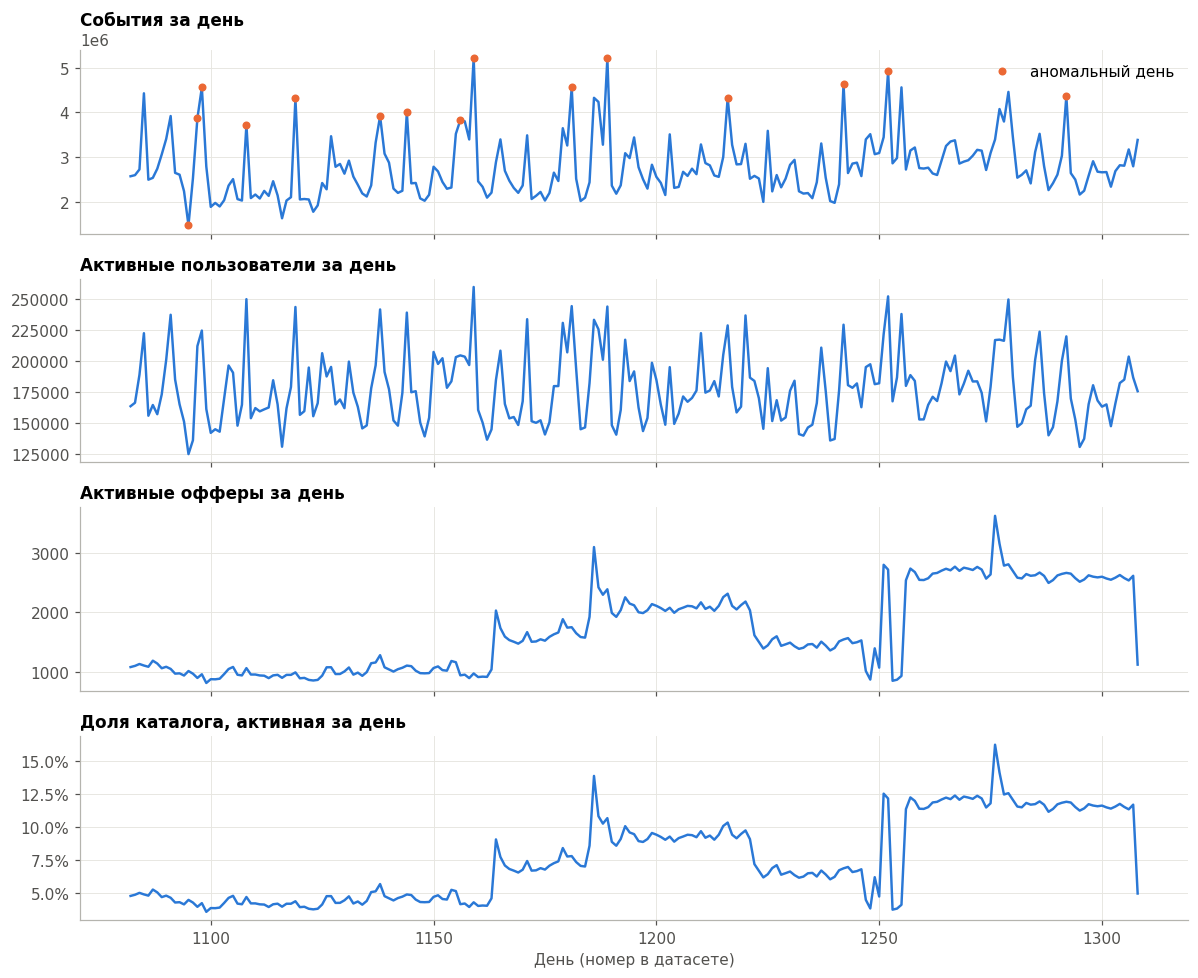

In [31]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
panels = [("n_events", "События за день"), ("n_users", "Активные пользователи за день"),
          ("n_items", "Активные офферы за день"), ("share_catalog", "Доля каталога, активная за день")]
for ax, (col, title) in zip(axes, panels):
    ax.plot(daily["day"], daily[col], color=BLUE)
    ax.set_title(title, loc="left")

# аномальные дни из п. 1.8 отмечаем точками
anom = daily_anom.filter((pl.col("ratio") > 1.5) | (pl.col("ratio") < 0.67))
axes[0].scatter(anom["day"], anom["n_events"], color=ORANGE, s=18, zorder=3, label="аномальный день")
axes[0].legend(frameon=False)
axes[3].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[-1].set_xlabel("День (номер в датасете)")
fig.tight_layout()
plt.show()

**Время суток и день недели**

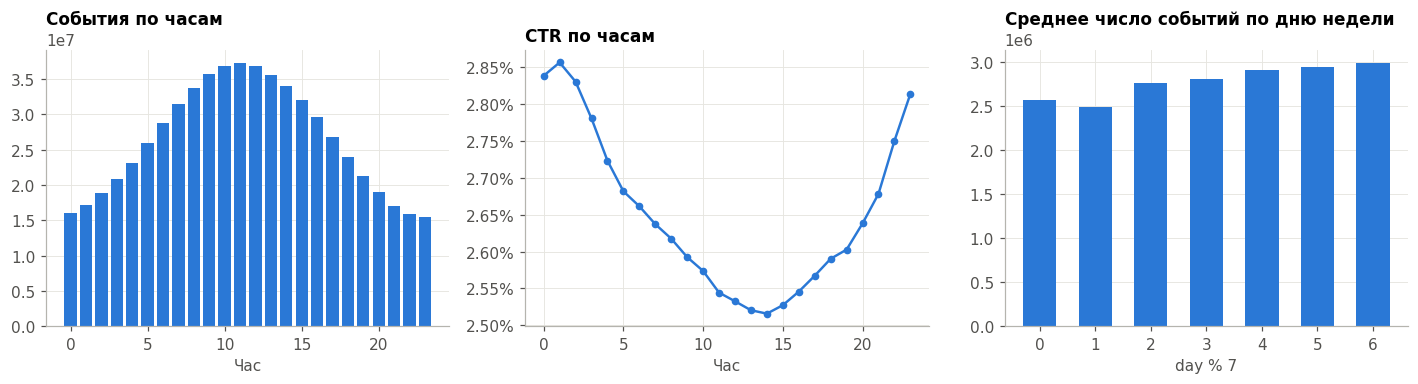

In [32]:
by_hour = (
    events.with_columns((pl.col("timestamp").dt.total_hours() % 24).alias("hour"))
    .group_by("hour")
    .agg(
        pl.len().alias("n_events"),
        (pl.col("action_type") == "view").sum().alias("n_view"),
        (pl.col("action_type") == "click").sum().alias("n_click"),
    )
    .sort("hour")
    .collect(engine="streaming")
    .with_columns((pl.col("n_click") / pl.col("n_view")).alias("ctr"))
)
by_weekday = (
    daily.with_columns((pl.col("day") % 7).alias("weekday"))
    .group_by("weekday").agg(pl.col("n_events").mean())
    .sort("weekday")
)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].bar(by_hour["hour"], by_hour["n_events"], color=BLUE, width=0.8)
axes[0].set_title("События по часам", loc="left"); axes[0].set_xlabel("Час")
axes[1].plot(by_hour["hour"], by_hour["ctr"], color=BLUE, marker="o", markersize=4)
axes[1].set_title("CTR по часам", loc="left"); axes[1].set_xlabel("Час")
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0, decimals=2))
axes[2].bar(by_weekday["weekday"], by_weekday["n_events"], color=BLUE, width=0.6)
axes[2].set_title("Среднее число событий по дню недели", loc="left"); axes[2].set_xlabel("day % 7")
fig.tight_layout()
plt.show()

**Пользователи: регион и соцдем**

Регионов: 91; топ-5 дают 36.5% пользователей


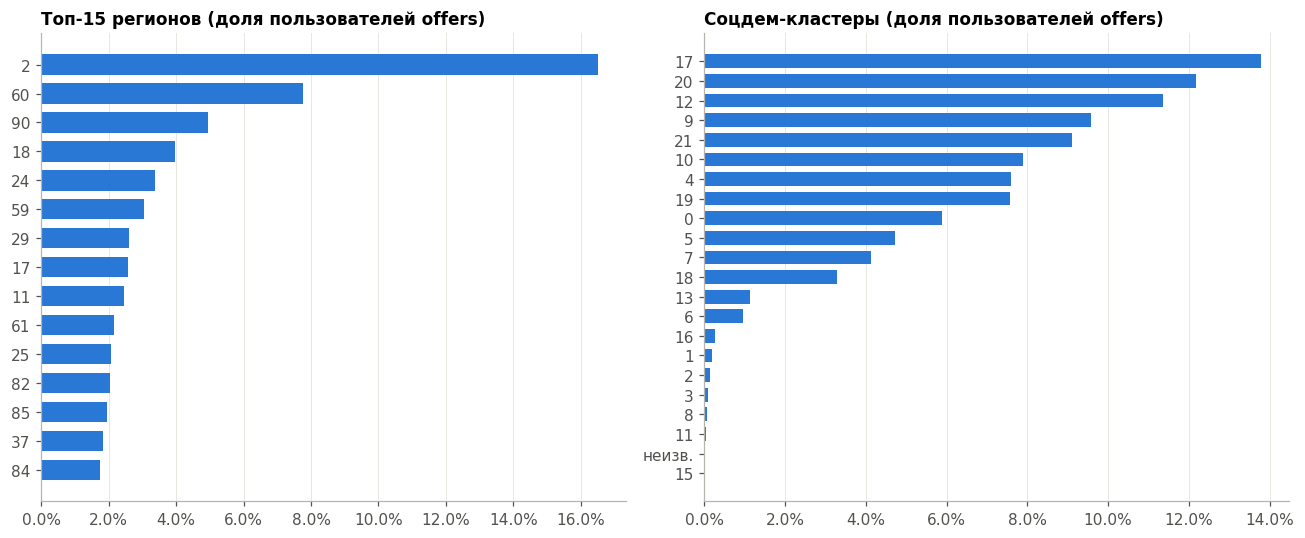

In [33]:
act = (
    users.join(user_stats.select("user_id"), on="user_id", how="semi")
    .with_columns(pl.col("region", "socdem_cluster").fill_null(255))
)

def shares(col):
    return (act[col].value_counts()
            .with_columns((pl.col("count") / pl.col("count").sum()).alias("share"))
            .sort("share"))

reg, soc = shares("region"), shares("socdem_cluster")
print(f"Регионов: {reg.height}; топ-5 дают {reg['share'].tail(5).sum():.1%} пользователей")

label = lambda v: "неизв." if v == 255 else str(v)
top_reg = reg.tail(15)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].barh([label(v) for v in top_reg["region"]], top_reg["share"], color=BLUE, height=0.7)
axes[0].set_title("Топ-15 регионов (доля пользователей offers)", loc="left")
axes[1].barh([label(v) for v in soc["socdem_cluster"]], soc["share"], color=BLUE, height=0.7)
axes[1].set_title("Соцдем-кластеры (доля пользователей offers)", loc="left")
for ax in axes:
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

**Активность пользователей, офферов и брендов** (логарифмические шкалы)

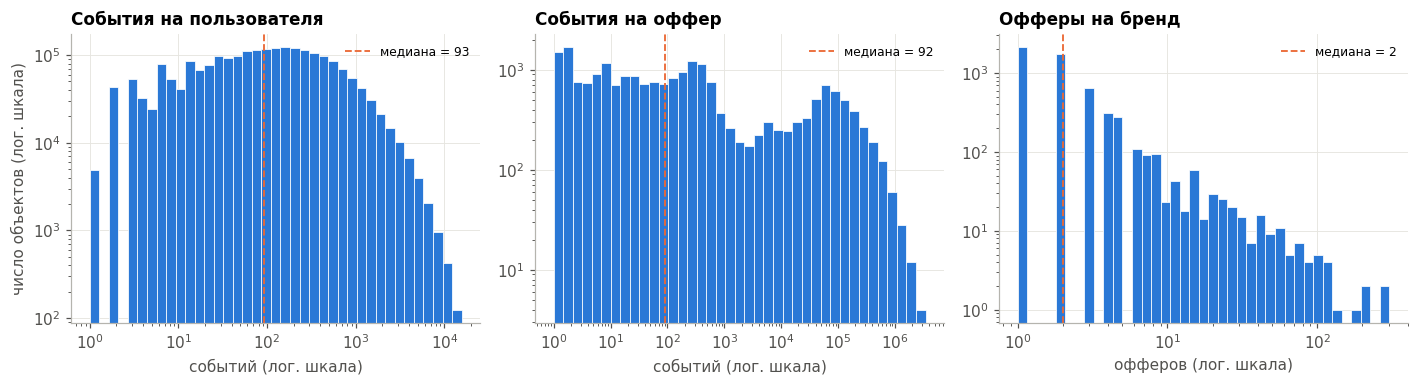

In [34]:
offers_per_brand = items.filter(pl.col("brand_id").is_not_null()).group_by("brand_id").len()["len"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, s, title, xlabel in [
    (axes[0], user_stats["n_events"], "События на пользователя", "событий (лог. шкала)"),
    (axes[1], item_stats["n_events"], "События на оффер", "событий (лог. шкала)"),
    (axes[2], offers_per_brand, "Офферы на бренд", "офферов (лог. шкала)"),
]:
    bins = np.logspace(0, np.log10(s.max()) + 0.01, 40)  # логарифмические корзины
    ax.hist(s.to_numpy(), bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axvline(s.median(), color=ORANGE, linewidth=1.2, linestyle="--", label=f"медиана = {s.median():,.0f}")
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel)
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("число объектов (лог. шкала)")
fig.tight_layout()
plt.show()

**Эмбеддинги офферов**

Нормы эмбеддингов: min=1.0000, max=1.0000


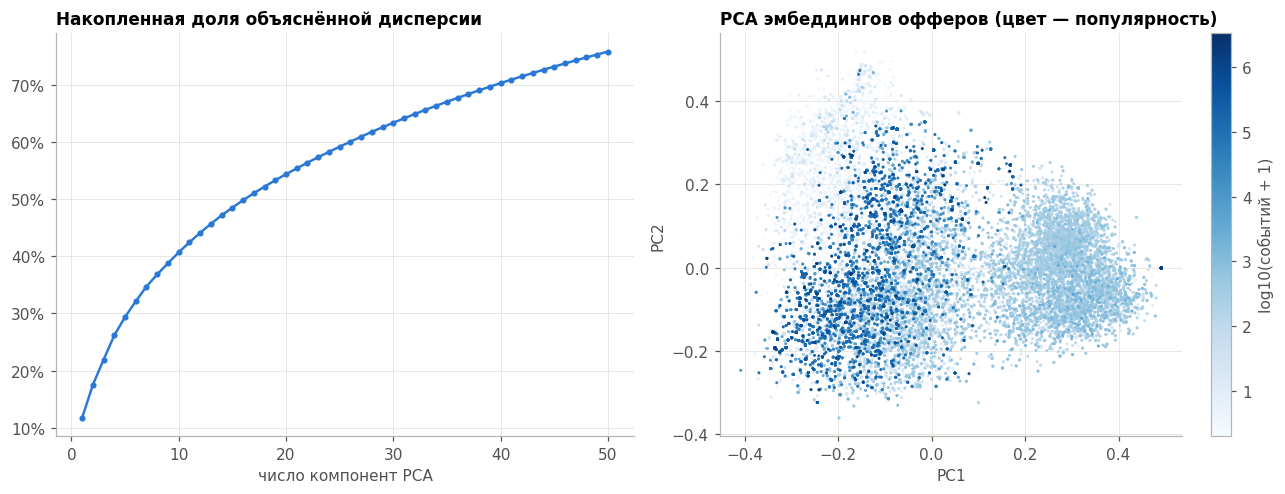

In [35]:
X = items["embedding"].to_numpy()
norms = np.linalg.norm(X, axis=1)
print(f"Нормы эмбеддингов: min={norms.min():.4f}, max={norms.max():.4f}")

pca = PCA(n_components=50).fit(X)
xy = pca.transform(X)[:, :2]
pop = (items.join(item_stats.select("item_id", "n_events"), on="item_id", how="left")
       ["n_events"].fill_null(0).to_numpy())
order = np.argsort(pop)  # популярные рисуем последними, поверх остальных

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(np.arange(1, 51), np.cumsum(pca.explained_variance_ratio_), color=BLUE, marker="o", markersize=3)
axes[0].set_title("Накопленная доля объяснённой дисперсии", loc="left")
axes[0].set_xlabel("число компонент PCA")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
sc = axes[1].scatter(xy[order, 0], xy[order, 1], c=np.log10(pop[order] + 1), cmap="Blues", s=4, linewidths=0)
axes[1].set_title("PCA эмбеддингов офферов (цвет — популярность)", loc="left")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
fig.colorbar(sc, ax=axes[1], label="log10(событий + 1)")
fig.tight_layout()
plt.show()

На PCA видны два облака. Проверим, чем они отличаются по популярности (границу PC1 = 0.1 взяли по графику):

In [36]:
items_pca = items.select("item_id").with_columns(
    pl.Series("pc1", xy[:, 0]),
    pl.Series("n_events", pop),
).with_columns((pl.col("pc1") > 0.1).alias("right_cluster"))

display(items_pca.group_by("right_cluster").agg(
    pl.len().alias("offers"),
    pl.col("n_events").median().alias("median_events"),
    pl.col("n_events").quantile(0.9).alias("q90_events"),
    (pl.col("n_events") >= 10_000).mean().alias("share_mass"),  # доля «массовых»
))

right_cluster,offers,median_events,q90_events,share_mass
bool,u32,f64,f64,f64
false,15454,47.0,104126.0,0.268086
true,6914,152.0,697.0,0.027047


**Выводы**

**Действия.** 96.9% событий - показы, 2.5% - клики, 0.53% - переходы к партнёру (`clickout`), 0.05% - лайки. Клик на показ 2.6%, до перехода к партнёру доходит 21% кликов. Лайков слишком мало, чтобы использовать их как таргет

**Динамика.** Число событий и активных пользователей колеблется вместе, с регулярными всплесками. С числом офферов всплески не совпадают, так что это волны активности аудитории (скорее всего, рассылки). Число активных офферов меняется ступеньками: около 1 000 в начале, около 2 000 в середине, провал до 900 возле дня 1250 и 2 600-2 700 в конце. Офферы запускают и снимают пачками, поэтому тест будет на другом каталоге, чем начало train, и модель должна справляться с новыми офферами

**Время суток и день недели.** Пик активности в 10-12 часов, минимум около полуночи (в каком часовом поясе timestamp, в документации не сказано). CTR ведёт себя наоборот: в часы пик он минимальный (около 2.5%), ночью максимальный (около 2.9%). Час суток можно взять как признак. Недельная сезонность слабая, дни отличаются не больше чем на 10% (день недели условный, `day % 7`)

**Пользователи.** Регион 2 - это 16.5% пользователей offers, на топ-5 регионов приходится 36.5%, дальше длинный хвост. Из 22 соцдем-кластеров крупных около 12, в остальных меньше 1% пользователей. Редкие кластеры для модели объединим в "прочие"

**Активность.** События на пользователя распределены примерно логнормально (медиана 93). У офферов распределение двугорбое: нишевые (до ~10³ событий) и массовые (10⁴-10⁵). Число офферов на бренд похоже на степенной закон: у большинства брендов 1-2 оффера, у единиц сотни

**Эмбеддинги офферов.** Все векторы нормированы (длина 1), поэтому косинусное сходство считается простым скалярным произведением. Две главные компоненты объясняют около 17% дисперсии, 50 компонент около 76%, информация размазана по многим измерениям. На PCA два облака. Правое (6 914 офферов) однородное: медиана 152 события, массовых офферов (от 10⁴ событий) всего 2.7%. В левом (15 454) есть всё: почти все массовые офферы (27%) и много нишевых (медиана 47). С двумя горбами популярности облака совпадают не полностью, но правое похоже на отдельный тип офферов, которые показываются умеренно и почти не становятся массовыми. То есть по эмбеддингу кое-что можно понять о популярности оффера, а это пригодится для новых офферов

## 4. Таргет и его связь с признаками

### 4.1. Целевая переменная

Мы хотим рекомендовать пользователю офферы, на которые он кликнет. Таргет - был ли клик по офферу у пары user × item: 1, если был хотя бы один `click`, и 0, если оффер показывали, а клика не было

Почему клик:
- `view` - это показ, его делает приложение, а не пользователь
- `like` слишком редкий (0.05% событий)
- `clickout` (переход к партнёру) - сигнал сильнее, но в 5 раз реже клика. Его можно использовать как дополнительный таргет или как вес для позитивов

По выборке из п. 2 позитивы составляют около 3.9% пар (666 тыс. из 16.9 млн), классы сильно несбалансированы. Так как у 28% кликов нет показа, позитивы берём независимо от того, был ли `view`.

### 4.2. CTR по регионам и соцдем-кластерам

Берём топ-10 регионов и кластеры, в которых не меньше 1% пользователей. Ячейки, где меньше 200 пользователей, не показываем. Цвет - отклонение от среднего CTR: синий выше среднего, красный ниже

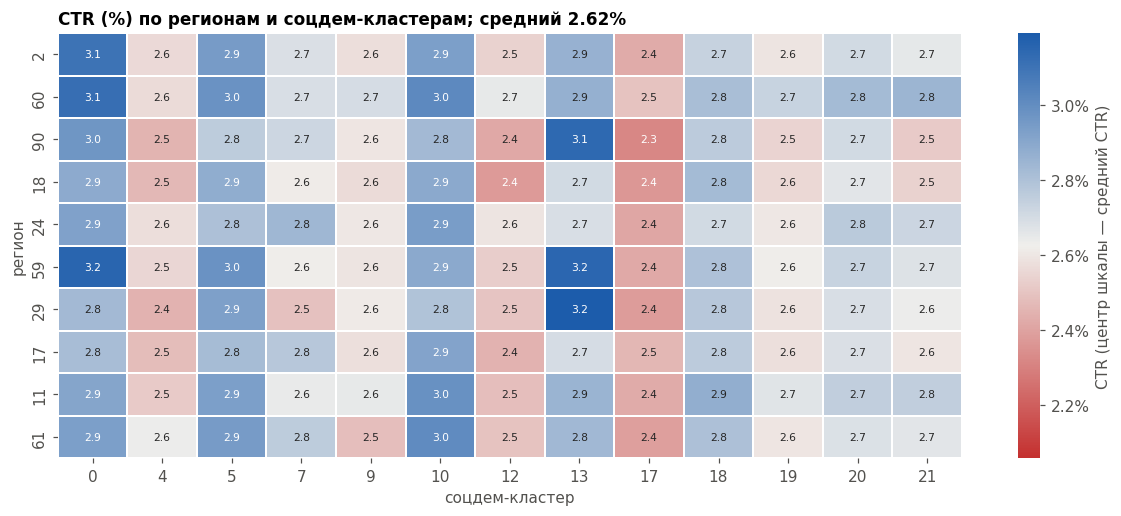

In [37]:
seg = users_ext.filter(pl.col("n_view") > 0).with_columns(pl.col("region", "socdem_cluster").fill_null(255))
top_regions = seg.group_by("region").agg(pl.len()).sort("len", descending=True).head(10)["region"]
big_socdem = seg.group_by("socdem_cluster").agg(pl.len()).filter(pl.col("len") / seg.height >= 0.01)["socdem_cluster"]

pivot = (
    seg.filter(pl.col("region").is_in(top_regions.implode()) & pl.col("socdem_cluster").is_in(big_socdem.implode()))
    .group_by("region", "socdem_cluster")
    .agg(pl.col("n_click").sum(), pl.col("n_view").sum(), pl.len().alias("users"))
    .with_columns(pl.when(pl.col("users") >= 200).then(pl.col("n_click") / pl.col("n_view")).alias("ctr"))
    .sort("socdem_cluster")
    .pivot(on="socdem_cluster", index="region", values="ctr")
)

order = pl.DataFrame({"region": top_regions, "_o": range(len(top_regions))})
pivot = pivot.join(order, on="region").sort("_o").drop("_o")

overall = seg["n_click"].sum() / seg["n_view"].sum()
DIVERGING = LinearSegmentedColormap.from_list("div", ["#c4302f", "#f0efec", "#1c5cab"])
mat = pivot.drop("region").to_numpy().astype(float)
dev = np.nanmax(np.abs(mat - overall))

fig, ax = plt.subplots(figsize=(11, 4.8))
sns.heatmap(mat, ax=ax, cmap=DIVERGING, norm=TwoSlopeNorm(vcenter=overall, vmin=overall - dev, vmax=overall + dev),
            annot=mat * 100, fmt=".1f", annot_kws={"fontsize": 7}, linewidths=1, linecolor="white",
            xticklabels=pivot.columns[1:], yticklabels=pivot["region"].to_list(),
            cbar_kws={"label": "CTR (центр шкалы — средний CTR)", "format": PercentFormatter(1.0, decimals=1)})
ax.set_xlabel("соцдем-кластер"); ax.set_ylabel("регион")
ax.set_title(f"CTR (%) по регионам и соцдем-кластерам; средний {overall:.2%}", loc="left")
fig.tight_layout()
plt.show()

### 4.3. Признаки оффера: корреляции и pairplot

Собираем признаки на уровне оффера, таргет здесь - CTR оффера. Берём офферы от 100 показов. Корреляцию считаем по Спирмену, потому что почти все распределения сильно скошены

In [38]:
item_time = (
    events.with_columns(pl.col("timestamp").dt.total_days().alias("day"))
    .group_by("item_id")
    .agg(
        pl.col("day").min().alias("first_day"),
        pl.col("day").max().alias("last_day"),
        pl.col("day").n_unique().alias("active_days"),
    )
    .collect(engine="streaming")
)
item_time.write_parquet("item_time.pq")  # пригодится в RecSys EDA (жизненный цикл офферов)

brand_size = items.group_by("brand_id").agg(pl.len().alias("brand_offers"))
brand_emb = brands_clean.select("brand_id", pl.col("embedding").is_not_null().alias("has_brand_emb"))

feat = (
    items.select("item_id", "brand_id")
    .with_columns(pl.Series("pc1", xy[:, 0])) # первая главная компонента из раздела 3
    .join(item_stats, on="item_id", how="left")
    .join(item_time, on="item_id", how="left")
    .join(brand_size, on="brand_id", how="left")
    .join(brand_emb, on="brand_id", how="left")
    .filter(pl.col("n_view") >= 100)
    .select(
        pl.col("n_view").log10().alias("log_views"),
        (pl.col("n_click") / pl.col("n_view")).alias("ctr"),
        (pl.col("n_clickout") / pl.col("n_view")).alias("clickout_per_view"),
        pl.col("active_days"),
        (pl.col("last_day") - pl.col("first_day") + 1).alias("lifetime_days"),
        pl.col("brand_offers").log10().fill_null(0).alias("log_brand_offers"),
        pl.col("brand_id").is_null().cast(pl.Int8).alias("no_brand"),
        pl.col("has_brand_emb").fill_null(False).cast(pl.Int8),
        pl.col("pc1"),
    )
)
print(f"Офферов в анализе: {feat.height:,}")

Офферов в анализе: 10,896


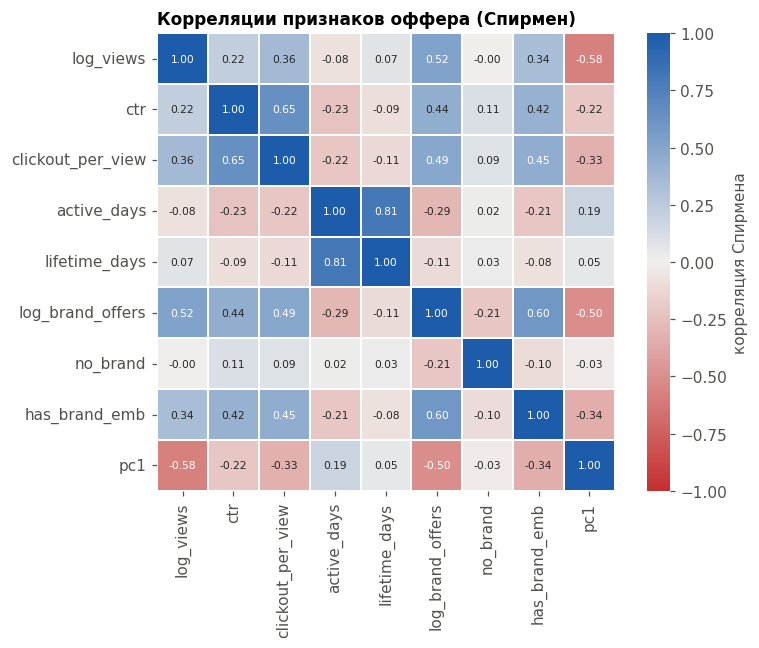

active_days         -0.233069
pc1                 -0.215569
lifetime_days       -0.087213
no_brand             0.105911
log_views            0.219036
has_brand_emb        0.417731
log_brand_offers     0.438296
clickout_per_view    0.645390
ctr                  1.000000
Name: ctr, dtype: float64


In [39]:
feat_nn = feat.drop_nulls()
ranks = feat_nn.select(pl.all().rank()).to_numpy()
corr = pd.DataFrame(np.corrcoef(ranks.T), index=feat_nn.columns, columns=feat_nn.columns)

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, ax=ax, cmap=DIVERGING, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 7}, linewidths=1, linecolor="white", square=True,
            cbar_kws={"label": "корреляция Спирмена"})
ax.set_title("Корреляции признаков оффера (Спирмен)", loc="left")
fig.tight_layout()
plt.show()

print(corr["ctr"].sort_values())  # связь каждого признака с таргетом

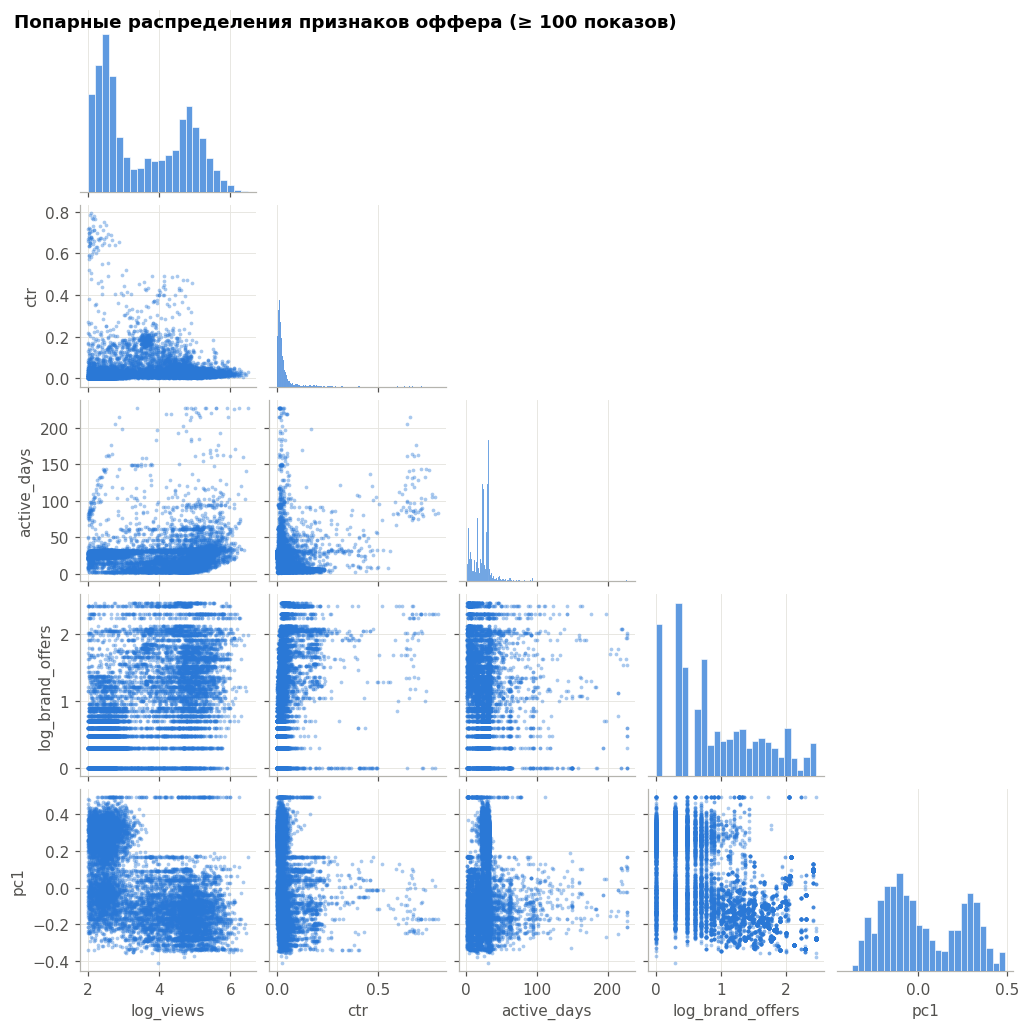

In [40]:
cols = ["log_views", "ctr", "active_days", "log_brand_offers", "pc1"]
pp = pd.DataFrame(feat.select(cols).to_numpy(), columns=cols)
g = sns.pairplot(pp, corner=True, height=1.9,
                 plot_kws={"s": 6, "alpha": 0.4, "color": BLUE, "linewidth": 0},
                 diag_kws={"color": BLUE, "edgecolor": "white"})
g.fig.suptitle("Попарные распределения признаков оффера (≥ 100 показов)", x=0.02, ha="left", fontweight="bold")
plt.show()

**Выводы**

**Регион × кластер.** Средний CTR 2.62%, в ячейках от 2.3% до 3.2%. Картину задаёт в основном кластер: 0, 5, 10 и 13 выше среднего почти во всех регионах, 17, 4 и 12 ниже. Между регионами разница меньше (2 и 60 чуть выше, 90 и 18 чуть ниже). Соцдем-кластер полезнее региона, но разброс всего ±20% от среднего, так что одним соцдемом персонализацию не сделать

**Признаки оффера:**
- сильнее всего с CTR связаны размер бренда (`log_brand_offers`, +0.44) и наличие у бренда эмбеддинга (+0.42). Между собой они тоже связаны (+0.60), это сходится с п. 1.5: эмбеддинги есть у крупных брендов
- популярность оффера (`log_views`) с CTR связана слабо (+0.22). На pairplot есть группа нишевых офферов с малым числом показов и очень высоким CTR (0.6-0.8)
- офферы, которые показываются дольше, кликают реже (`active_days`, −0.23), возможно, пользователи к ним привыкают. `active_days` и `lifetime_days` связаны (+0.81), но не одно и то же: у офферов бывают перерывы
- `pc1` связана с популярностью (−0.58) и размером бренда (−0.50): одно из облаков PCA - это офферы мелких брендов с небольшим числом показов
- `clickout_per_view` сильно коррелирует с CTR (+0.65), но это то же самое поведение, как признак её брать нельзя (утечка таргета)

Горизонтальная полоса `pc1 ≈ 0.49` на pairplot - это те самые 347 офферов с одинаковым «пустым» эмбеддингом из п. 1.7

## 5. RecSys EDA

### 5.1. Длинный хвост: кривые Лоренца и коэффициент Джини

По оси X доля объектов от наименее активных, по Y доля событий, которая на них приходится. Коэффициент Джини: 0 - все одинаково активны, 1 - все события у одного объекта.

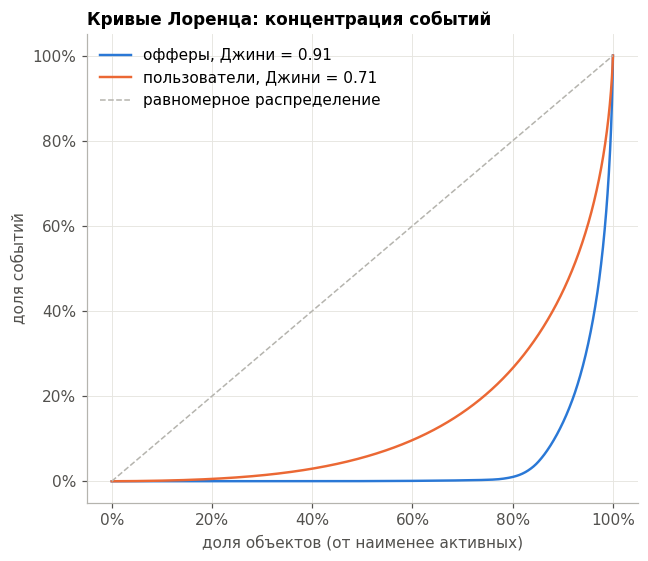

In [41]:
def lorenz(counts):
    x = np.sort(counts.to_numpy())
    cum = np.concatenate([[0], np.cumsum(x) / x.sum()])
    share_obj = np.linspace(0, 1, len(cum))
    gini = 1 - 2 * np.trapezoid(cum, share_obj)
    return share_obj, cum, gini

fig, ax = plt.subplots(figsize=(6, 5.2))
for counts, name, color in [(item_stats["n_events"], "офферы", BLUE),
                            (user_stats["n_events"], "пользователи", ORANGE)]:
    xs, ys, g = lorenz(counts)
    ax.plot(xs, ys, color=color, label=f"{name}, Джини = {g:.2f}")
ax.plot([0, 1], [0, 1], color="#b5b4ae", linestyle="--", linewidth=1, label="равномерное распределение")
ax.set_xlabel("доля объектов (от наименее активных)"); ax.set_ylabel("доля событий")
ax.xaxis.set_major_formatter(PercentFormatter(1.0)); ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_title("Кривые Лоренца: концентрация событий", loc="left")
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

### 5.2. Сколько кликов у пользователей

In [42]:
print(user_stats.select(
    (pl.col("n_click") == 0).mean().alias("0 кликов"),
    (pl.col("n_click") == 1).mean().alias("1 клик"),
    pl.col("n_click").is_between(2, 4).mean().alias("2–4"),
    pl.col("n_click").is_between(5, 19).mean().alias("5–19"),
    (pl.col("n_click") >= 20).mean().alias("20+"),
))

shape: (1, 5)
┌──────────┬──────────┬──────────┬──────────┬──────────┐
│ 0 кликов ┆ 1 клик   ┆ 2–4      ┆ 5–19     ┆ 20+      │
│ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞══════════╪══════════╪══════════╪══════════╪══════════╡
│ 0.445559 ┆ 0.023734 ┆ 0.233389 ┆ 0.207547 ┆ 0.089771 │
└──────────┴──────────┴──────────┴──────────┴──────────┘


Пользователей ровно с одним кликом подозрительно мало. Посмотрим распределение точнее и проверим, что это не двойная запись:

In [43]:
click_dist = (
    user_stats.filter(pl.col("n_click") > 0)
    .select(pl.col("n_click").clip(upper_bound=10))
    .to_series().value_counts().sort("n_click")
)
print(click_dist)

# пользователи ровно с 2 кликами: по разным ли офферам и с каким интервалом
two_clicks = (
    events.filter(pl.col("action_type") == "click")
    .group_by("user_id")
    .agg(
        pl.len().alias("n"),
        pl.col("item_id").n_unique().alias("items"),
        (pl.col("timestamp").max() - pl.col("timestamp").min()).dt.total_hours().alias("hours"),
    )
    .filter(pl.col("n") == 2)
    .collect(engine="streaming")
)
print(f"Пользователей ровно с 2 кликами: {two_clicks.height:,}; "
      f"оба клика по разным офферам: {(two_clicks['items'] == 2).mean():.1%}; "
      f"медианный интервал между кликами: {two_clicks['hours'].median():.1f} ч")

shape: (10, 2)
┌─────────┬────────┐
│ n_click ┆ count  │
│ ---     ┆ ---    │
│ u32     ┆ u32    │
╞═════════╪════════╡
│ 1       ┆ 52613  │
│ 2       ┆ 302636 │
│ 3       ┆ 90030  │
│ 4       ┆ 124701 │
│ 5       ┆ 68456  │
│ 6       ┆ 69866  │
│ 7       ┆ 49254  │
│ 8       ┆ 45102  │
│ 9       ┆ 36210  │
│ 10      ┆ 390196 │
└─────────┴────────┘
Пользователей ровно с 2 кликами: 302,636; оба клика по разным офферам: 97.7%; медианный интервал между кликами: 6.0 ч


### 5.3. Жизненный цикл офферов

Время жизни считаем от первого до последнего события оффера. Первая неделя на графике новых офферов завышена: в неё попали все офферы, запущенные до начала данных.

shape: (1, 5)
┌──────┬───────┬──────┬───────┬───────┐
│ q0.1 ┆ q0.25 ┆ q0.5 ┆ q0.75 ┆ q0.9  │
│ ---  ┆ ---   ┆ ---  ┆ ---   ┆ ---   │
│ f64  ┆ f64   ┆ f64  ┆ f64   ┆ f64   │
╞══════╪═══════╪══════╪═══════╪═══════╡
│ 1.0  ┆ 13.0  ┆ 28.0 ┆ 38.0  ┆ 136.0 │
└──────┴───────┴──────┴───────┴───────┘


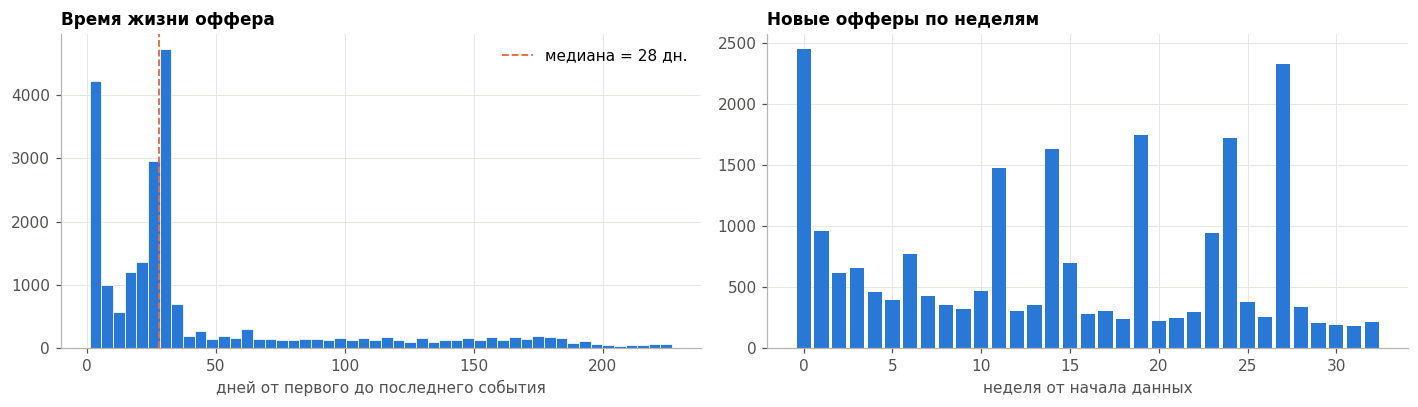

In [44]:
life = item_time.with_columns((pl.col("last_day") - pl.col("first_day") + 1).alias("lifetime_days"))
print(life.select(pl.col("lifetime_days").quantile(q).alias(f"q{q}") for q in [0.1, 0.25, 0.5, 0.75, 0.9]))

day0 = life["first_day"].min()
new_per_week = (
    life.with_columns(((pl.col("first_day") - day0) // 7).alias("week"))
    .group_by("week").agg(pl.len().alias("new_offers")).sort("week")
)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(life["lifetime_days"].to_numpy(), bins=50, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].axvline(life["lifetime_days"].median(), color=ORANGE, linestyle="--", linewidth=1.2,
                label=f"медиана = {life['lifetime_days'].median():.0f} дн.")
axes[0].set_title("Время жизни оффера", loc="left")
axes[0].set_xlabel("дней от первого до последнего события"); axes[0].legend(frameon=False)
axes[1].bar(new_per_week["week"], new_per_week["new_offers"], color=BLUE, width=0.8)
axes[1].set_title("Новые офферы по неделям", loc="left"); axes[1].set_xlabel("неделя от начала данных")
fig.tight_layout()
plt.show()

### 5.4. Холодный старт и выбор сплита

Для теста длиной 7, 14 и 28 последних дней смотрим, какая доля тестовых кликов приходится на пользователей и офферы, которых не было в train, и сколько кликов повторные (пара уже кликалась в train).

In [45]:
clicks = (
    events.filter(pl.col("action_type") == "click")
    .select("user_id", "item_id", pl.col("timestamp").dt.total_days().alias("day"))
    .collect(engine="streaming")
)
day_max = clicks["day"].max()

rows = []
for test_days in [7, 14, 28]:
    T = day_max - test_days + 1  # первый день теста
    train_ev = events.filter(pl.col("timestamp").dt.total_days() < T)
    train_users = train_ev.select("user_id").unique().collect(engine="streaming")
    train_items = train_ev.select("item_id").unique().collect(engine="streaming")
    train_pairs = clicks.filter(pl.col("day") < T).select("user_id", "item_id").unique()
    test = clicks.filter(pl.col("day") >= T)
    rows.append({
        "test_days": test_days,
        "test_clicks": test.height,
        "cold_user": test.join(train_users, on="user_id", how="anti").height / test.height,
        "cold_item": test.join(train_items, on="item_id", how="anti").height / test.height,
        "repeat_click": test.join(train_pairs, on=["user_id", "item_id"], how="semi").height / test.height,
    })
print(pl.DataFrame(rows))

shape: (3, 5)
┌───────────┬─────────────┬───────────┬───────────┬──────────────┐
│ test_days ┆ test_clicks ┆ cold_user ┆ cold_item ┆ repeat_click │
│ ---       ┆ ---         ┆ ---       ┆ ---       ┆ ---          │
│ i64       ┆ i64         ┆ f64       ┆ f64       ┆ f64          │
╞═══════════╪═════════════╪═══════════╪═══════════╪══════════════╡
│ 7         ┆ 499841      ┆ 0.021313  ┆ 0.286723  ┆ 0.082196     │
│ 14        ┆ 950991      ┆ 0.027969  ┆ 0.435489  ┆ 0.059712     │
│ 28        ┆ 1892724     ┆ 0.038801  ┆ 0.559577  ┆ 0.031121     │
└───────────┴─────────────┴───────────┴───────────┴──────────────┘


**Выводы**

**Концентрация.** Джини 0.91 у офферов и 0.71 у пользователей. По офферам концентрация гораздо сильнее, так что popularity bias будет главной проблемой: бейзлайн по популярности окажется сильным, и кроме точности нужно смотреть на покрытие каталога

**История пользователей.** 45% пользователей offers ни разу не кликнули. Для них нет позитивной истории, остаются популярность, соцдем и показы. В распределении числа кликов есть странность: ровно с одним кликом всего 2.4% пользователей, а с 2-4 кликами 23%. Пользователей ровно с 2 кликами в разы больше, чем с одним, и почти всегда это клики по разным офферам с разницей в несколько часов, то есть не двойная запись. Возможно, это особенность самого продукта, документация её не объясняет

**Жизненный цикл офферов.** Время жизни двугорбое: короткие акции на 1-3 дня и месячные кампании (пик около 28-30 дней, медиана 28). 10% офферов живут дольше 136 дней. Новые офферы приходят пачками раз в 3-5 недель (до 2 300 за неделю при обычных 200-700), отсюда и ступеньки в числе активных офферов.

**Холодный старт.**

| Тест | Кликов в тесте | Холодные пользователи | Холодные офферы | Повторные клики |
|---|---|---|---|---|
| 7 дней | 500 тыс. | 2.1% | 28.7% | 8.2% |
| 14 дней | 951 тыс. | 2.8% | 43.5% | 6.0% |
| 28 дней | 1.89 млн | 3.9% | 56.0% | 3.1% |

Холодных пользователей мало (2-4%), а с офферами наоборот: даже при тесте в 7 дней почти треть кликов приходится на офферы, которых не было в train. Чисто коллаборативные модели (ALS и т. п.) на них работать не будут, нужны эмбеддинги офферов и брендов. Повторных кликов 3-8%, поэтому уже кликнутые офферы нельзя просто выкидывать из рекомендаций.

**Разбиение.** Тест - последние 7 дней (500 тыс. кликов хватает, а холодных офферов здесь меньше всего), валидация - 7 дней перед ним, остальное train. Качество будем смотреть отдельно на "тёплых" и "холодных" офферах

## 6. Другие домены

Payments есть только в полной версии датасета, в Small его нет, поэтому смотрим retail, marketplace и reviews

In [46]:
domains = {
    "offers": pl.scan_parquet(PATH / "offers/events/*.pq"),
    "retail": pl.scan_parquet(PATH / "retail/events/*.pq"),
    "marketplace": pl.scan_parquet(PATH / "marketplace/events/*.pq"),
    "reviews": pl.scan_parquet(PATH / "reviews/*.pq"),
}

rows = []
for name, ev in domains.items():
    obj = pl.col("brand_id") if name == "reviews" else pl.col("item_id")  # в reviews нет товаров, только бренды
    rows.append(ev.select(
        pl.lit(name).alias("domain"),
        pl.len().alias("events"),
        pl.col("user_id").n_unique().alias("users"),
        obj.n_unique().alias("items_or_brands"),
        pl.col("timestamp").dt.total_days().min().alias("day_min"),
        pl.col("timestamp").dt.total_days().max().alias("day_max"),
    ).collect(engine="streaming"))
overview = pl.concat(rows)
print(overview)

for name in ["retail", "marketplace"]:
    print(domains[name].group_by("action_type").agg(pl.len().alias("n"))
            .collect(engine="streaming")
            .with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
            .sort("n", descending=True))

shape: (4, 6)
┌─────────────┬───────────┬─────────┬─────────────────┬─────────┬─────────┐
│ domain      ┆ events    ┆ users   ┆ items_or_brands ┆ day_min ┆ day_max │
│ ---         ┆ ---       ┆ ---     ┆ ---             ┆ ---     ┆ ---     │
│ str         ┆ u32       ┆ u32     ┆ u32             ┆ i64     ┆ i64     │
╞═════════════╪═══════════╪═════════╪═════════════════╪═════════╪═════════╡
│ offers      ┆ 633207032 ┆ 2216762 ┆ 22368           ┆ 1082    ┆ 1308    │
│ retail      ┆ 267043972 ┆ 140062  ┆ 257327          ┆ 1082    ┆ 1308    │
│ marketplace ┆ 130447117 ┆ 1616763 ┆ 2325409         ┆ 1082    ┆ 1308    │
│ reviews     ┆ 363970    ┆ 103834  ┆ 24467           ┆ 1082    ┆ 1308    │
└─────────────┴───────────┴─────────┴─────────────────┴─────────┴─────────┘
shape: (4, 3)
┌───────────────┬───────────┬──────────┐
│ action_type   ┆ n         ┆ share    │
│ ---           ┆ ---       ┆ ---      │
│ str           ┆ u32       ┆ f64      │
╞═══════════════╪═══════════╪══════════╡
│ view 

Каталог retail, поверхности показа и отзывы:

In [47]:
# каталог retail: есть ли товары из событий без описания и какие бренды (сети) в нём есть
retail_items = pl.read_parquet(PATH / "retail/items.pq", columns=["item_id", "brand_id"])
retail_ev_items = domains["retail"].select(pl.col("item_id").unique()).collect(engine="streaming")
missing = retail_ev_items.join(retail_items, on="item_id", how="anti").height
print(f"Товаров в каталоге retail: {retail_items.height:,}; в событиях: {retail_ev_items.height:,}; "
      f"нет в каталоге: {missing:,}")
print(retail_items["brand_id"].value_counts().sort("count", descending=True))

# на каких поверхностях происходят события
for name in ["retail", "marketplace"]:
    print(name)
    print(domains[name].group_by("subdomain").agg(pl.len().alias("n"))
          .collect(engine="streaming")
          .with_columns((pl.col("n") / pl.col("n").sum()).alias("share"))
          .sort("n", descending=True))

# отзывы: распределение оценок и заполненность текста
reviews = domains["reviews"].select("rating", "text").collect(engine="streaming")
print(reviews["rating"].value_counts().sort("rating")
      .with_columns((pl.col("count") / reviews.height).alias("share")))
print(f"Отзывов с текстом: {reviews['text'].is_not_null().mean():.1%}")

Товаров в каталоге retail: 250,856; в событиях: 257,327; нет в каталоге: 8,521
shape: (8, 2)
┌──────────┬───────┐
│ brand_id ┆ count │
│ ---      ┆ ---   │
│ u64      ┆ u32   │
╞══════════╪═══════╡
│ 240838   ┆ 68380 │
│ 37799    ┆ 57826 │
│ 146468   ┆ 45297 │
│ 65693    ┆ 43048 │
│ 60434    ┆ 17694 │
│ 25989    ┆ 14991 │
│ 48632    ┆ 3617  │
│ 185133   ┆ 3     │
└──────────┴───────┘
retail
shape: (5, 3)
┌───────────┬───────────┬──────────┐
│ subdomain ┆ n         ┆ share    │
│ ---       ┆ ---       ┆ ---      │
│ str       ┆ u32       ┆ f64      │
╞═══════════╪═══════════╪══════════╡
│ catalog   ┆ 231285386 ┆ 0.866095 │
│ search    ┆ 21575005  ┆ 0.080792 │
│ other     ┆ 7433721   ┆ 0.027837 │
│ main      ┆ 3804123   ┆ 0.014245 │
│ i2i       ┆ 2945737   ┆ 0.011031 │
└───────────┴───────────┴──────────┘
marketplace
shape: (6, 3)
┌───────────┬──────────┬──────────┐
│ subdomain ┆ n        ┆ share    │
│ ---       ┆ ---      ┆ ---      │
│ str       ┆ u32      ┆ f64      │
╞═══════════╪══

**Выводы**

| Домен | Событий | Пользователей | Товаров / брендов | Действия |
|---|---|---|---|---|
| offers | 633.2 млн | 2.22 млн | 22.4 тыс. офферов | view, click, clickout, like |
| retail | 267.0 млн | 140 тыс. | 257 тыс. товаров | view, order, added_to_cart, click |
| marketplace | 130.4 млн | 1.62 млн | 2.33 млн товаров | view, click, clickout, like |
| reviews | 364 тыс. отзывов | 104 тыс. | 24.5 тыс. брендов | оценка 1-5 |

- **marketplace** по событиям похож на offers: те же действия и похожий CTR (3%), но каталог огромный. Большая часть событий приходится на поверхность `u2i`, то есть на персональные рекомендации, и данные уже смещены работающей рекомендательной системой
- **retail** - обычная воронка магазина: просмотр, клик, корзина, заказ. `brand_id` здесь означает продуктовую сеть, и сетей всего 8. Заказов (7.4 млн) больше, чем добавлений в корзину (3.9 млн): заказы пишутся отдельно с `subdomain = other`, а корзина логируется не во всех сценариях. Ещё в событиях retail встречаются товары, которых нет в каталоге
- **reviews** - отзывы о брендах, а не о товарах. Оценки сильно скошены, почти все ставят 5. Эмбеддинги отзывов размерности 312, как у офферов. В данных есть колонка `text`, заполненная у небольшой части отзывов (тексты на английском), хотя в документации написано, что сырого текста нет

## 7. Можно ли объединять домены

### 7.1. По пользователям

In [48]:
users_by_domain = {n: ev.select("user_id").unique().collect(engine="streaming") for n, ev in domains.items()}
offers_users = users_by_domain["offers"]
no_click = user_stats.filter(pl.col("n_click") == 0).select("user_id")  # пользователи offers без кликов

rows = []
for n in ["retail", "marketplace", "reviews"]:
    other = users_by_domain[n]
    inter = offers_users.join(other, on="user_id", how="semi").height
    rows.append({
        "domain": n,
        "users": other.height,
        "also_in_offers": inter / other.height,                 # доля пользователей домена, есть в offers
        "share_of_offers_users": inter / offers_users.height,   # доля пользователей offers, есть в домене
        "share_of_offers_no_click": no_click.join(other, on="user_id", how="semi").height / no_click.height,
    })
print(pl.DataFrame(rows))

shape: (3, 5)
┌─────────────┬─────────┬────────────────┬───────────────────────┬──────────────────────────┐
│ domain      ┆ users   ┆ also_in_offers ┆ share_of_offers_users ┆ share_of_offers_no_click │
│ ---         ┆ ---     ┆ ---            ┆ ---                   ┆ ---                      │
│ str         ┆ i64     ┆ f64            ┆ f64                   ┆ f64                      │
╞═════════════╪═════════╪════════════════╪═══════════════════════╪══════════════════════════╡
│ retail      ┆ 140062  ┆ 0.991325       ┆ 0.062635              ┆ 0.008789                 │
│ marketplace ┆ 1616763 ┆ 0.839251       ┆ 0.612095              ┆ 0.509452                 │
│ reviews     ┆ 103834  ┆ 0.917696       ┆ 0.042985              ┆ 0.017291                 │
└─────────────┴─────────┴────────────────┴───────────────────────┴──────────────────────────┘


### 7.2. По брендам

In [49]:
brand_sets = {
    "retail": pl.scan_parquet(PATH / "retail/items.pq").select(pl.col("brand_id").drop_nulls().unique()).collect(),
    "marketplace": pl.scan_parquet(PATH / "marketplace/items.pq").select(pl.col("brand_id").drop_nulls().unique()).collect(),
    "reviews": domains["reviews"].select(pl.col("brand_id").drop_nulls().unique()).collect(engine="streaming"),
}
offer_brands = (
    items.join(item_stats, on="item_id", how="left")
    .filter(pl.col("brand_id").is_not_null())
    .group_by("brand_id").agg(pl.col("n_events").sum(), pl.col("n_view").sum(), pl.col("n_click").sum())
)

rows = []
for n, b in brand_sets.items():
    m = offer_brands.join(b, on="brand_id", how="semi")
    rows.append({
        "domain": n, "brands_in_domain": b.height, "common_brands": m.height,
        "share_offer_brands": m.height / offer_brands.height,
        "share_offer_events": m["n_events"].sum() / offer_brands["n_events"].sum(),
        "share_offer_clicks": m["n_click"].sum() / offer_brands["n_click"].sum(),
    })
print(pl.DataFrame(rows))

shape: (3, 6)
┌─────────────┬─────────────────┬───────────────┬────────────────┬────────────────┬────────────────┐
│ domain      ┆ brands_in_domai ┆ common_brands ┆ share_offer_br ┆ share_offer_ev ┆ share_offer_cl │
│ ---         ┆ n               ┆ ---           ┆ ands           ┆ ents           ┆ icks           │
│ str         ┆ ---             ┆ i64           ┆ ---            ┆ ---            ┆ ---            │
│             ┆ i64             ┆               ┆ f64            ┆ f64            ┆ f64            │
╞═════════════╪═════════════════╪═══════════════╪════════════════╪════════════════╪════════════════╡
│ retail      ┆ 8               ┆ 6             ┆ 0.001056       ┆ 0.112374       ┆ 0.149356       │
│ marketplace ┆ 231             ┆ 73            ┆ 0.012845       ┆ 0.12462        ┆ 0.118205       │
│ reviews     ┆ 24467           ┆ 814           ┆ 0.143234       ┆ 0.67822        ┆ 0.752707       │
└─────────────┴─────────────────┴───────────────┴────────────────┴───────────

### 7.3. Отзывы как признак бренда

In [50]:
brand_rating = (
    domains["reviews"].group_by("brand_id")
    .agg(pl.len().alias("n_reviews"), pl.col("rating").mean().alias("avg_rating"))
    .collect(engine="streaming")
)
br = (
    offer_brands.filter(pl.col("n_view") >= 1000)
    .with_columns((pl.col("n_click") / pl.col("n_view")).alias("ctr"))
    .join(brand_rating.filter(pl.col("n_reviews") >= 5), on="brand_id")
)
print(f"Брендов в анализе: {br.height}")
print(br.select(
    pl.corr("avg_rating", "ctr", method="spearman").alias("rho_rating_ctr"),
    pl.corr("n_reviews", "ctr", method="spearman").alias("rho_nreviews_ctr"),
))

Брендов в анализе: 246
shape: (1, 2)
┌────────────────┬──────────────────┐
│ rho_rating_ctr ┆ rho_nreviews_ctr │
│ ---            ┆ ---              │
│ f64            ┆ f64              │
╞════════════════╪══════════════════╡
│ -0.091698      ┆ 0.460439         │
└────────────────┴──────────────────┘


### 7.4. По товарам

Префиксы `item_id` разные (`offer_`, `fmcg_`, `nfmcg_`), пересечений нет. Да и товар маркетплейса и оффер - разные вещи (товар и акция партнёра), так что по товарам домены напрямую не объединяются.

**Выводы**

**Пользователи.** Почти все пользователи других доменов есть и в offers (84-99%), база клиентов общая. В обратную сторону по-разному: retail и reviews покрывают только 6% и 4% пользователей offers, а marketplace 61% пользователей offers и 51% тех, кто в offers ни разу не кликал. Значит, поведение в marketplace можно использовать как признаки пользователя, в том числе для половины "холодных".

**Бренды.** Общих брендов мало, но это крупнейшие партнёры:

| Домен | Брендов в домене | Общих с offers | Доля брендов offers | Доля событий offers | Доля кликов offers |
|---|---|---|---|---|---|
| retail | 8 | 6 | 0.1% | 11% | 15% |
| marketplace | 231 | 73 | 1.3% | 12% | 12% |
| reviews | 24 467 | 814 | 14% | 68% | 75% |

Через `brand_id` к офферу можно добавить признаки из других доменов: например, если пользователь покупает в сети X в retail, ему могут быть интересны офферы бренда X. Кстати, все 5 брендов с дублями из п. 1.2 оказались крупнейшими сетями retail

**Отзывы.** На 246 брендах (от 5 отзывов и от 1 000 показов в offers) средняя оценка с CTR не связана (ρ = −0.09, почти все ставят 5), а число отзывов связано умеренно (ρ = +0.46). Полезна не оценка, а то, насколько бренд известен, то есть примерно то же, что размер бренда в offers

**Товары.** По товарам объединить нельзя. Связать домены можно только через пользователя и бренд

## 8. Итоговые выводы

**Данные.** Домен offers: 633 млн событий за 227 дней (дни 1082-1308), 2.2 млн пользователей, 22.4 тыс. офферов, 5.7 тыс. брендов-партнёров. В событиях есть только время, пользователь, оффер и тип действия, в каталоге - бренд и эмбеддинг описания. Категорий, цен и поверхностей показа нет

**Качество данных**
- Пропусков немного, и ни один не случайный: офферы без бренда - отдельный тип предложений с высоким CTR, эмбеддинги есть только у крупных брендов, регион и соцдем не заполнены у малоактивных клиентов. Заполняли отдельными категориями и флагами, без средних и мод
- Ошибки: 5 брендов с несколькими строками в справочнике (свели к одной строке через центроид) и 1 дубль события (удалили)
- Неявные проблемы: 347 офферов с "пустым" эмбеддингом, у 72% офферов эмбеддинг совпадает с другими, у 28% кликов нет записанного показа
- Ботов нет, аномальные дни - это всплески активности, их оставили

**Главные свойства задачи**
1. Сильная концентрация: Джини 0.91 по офферам, 20% офферов дают 99% событий
2. Разреженность: заполнено 0.69% матрицы user × item, по кликам 0.027%; 45% пользователей не кликали ни разу
3. Каталог постоянно меняется: в день активно около 7.6% офферов, оффер обычно живёт около месяца, новые приходят пачками
4. Холодный старт по офферам: при тесте в 7 дней 29% кликов приходится на офферы, которых не было в train
5. Повторы: в среднем 1.9 события на пару, 3-8% тестовых кликов повторные

**Таргет.** Клик по офферу на уровне пары user × item, позитивов около 3.9%. CTR выше у офферов крупных брендов и ниже у долгоживущих офферов и в часы пик. Соцдем-кластер информативнее региона

**Другие домены.** Объединять можно только через пользователя и бренд. Marketplace покрывает 61% пользователей offers и половину тех, кто не кликал. Бренды из отзывов, retail и marketplace - это крупнейшие партнёры (75%, 15% и 12% кликов offers)